<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/Parcial-Primera-Unidad/Actividad2_CNN_EuroSAT_parcial_1era_unidad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Actividad 2 — Red Neuronal Convolucional sobre Dataset de Imagen Real

## SECCIÓN A — Presentación

| Campo | Detalle |
|---|---|
| **Curso** | Ingeniería del Conocimiento (ISO56B) |
| **Semestre** | 2026-II |
| **Fecha** | _[dd/mm/aaaa]_ |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |
| **Universidad** | Universidad Nacional del Centro del Perú — Facultad de Ingeniería de Sistemas |

**Integrantes**

| N° | Apellidos y nombres | Código |
|---|---|---|
| 1 | _Huaynalaya Alonzo Frank Elvis_ | _[Código]_ |
| 2 | _Quintanilla Condor Juan Josue_ | _[Código]_ |
| 3 | _Gomez Muñoz David Pedro_ | _[Código]_ |
| 4 | _Briceño Alaya Yimar Jesús_ | _[Código]_ |

**Dataset elegido:** EuroSAT (versión RGB) — 27 000 imágenes satelitales reales de 64×64 píxeles tomadas por el satélite **Sentinel-2** del programa europeo Copernicus, etiquetadas en **10 clases de uso y cobertura de suelo**:

| Clase (TFDS) | Nombre en español |
|---|---|
| AnnualCrop | Cultivo anual |
| Forest | Bosque |
| HerbaceousVegetation | Vegetación herbácea |
| Highway | Autopista |
| Industrial | Zona industrial |
| Pasture | Pastizal |
| PermanentCrop | Cultivo permanente |
| Residential | Residencial |
| River | Río |
| SeaLake | Lago o mar |

**Fuente:**
- TensorFlow Datasets: https://www.tensorflow.org/datasets/catalog/eurosat (se carga con `tfds.load('eurosat/rgb')`)
- Repositorio original: https://github.com/phelber/EuroSAT
- Artículo: Helber, P., Bischke, B., Dengel, A. y Borth, D. (2019). *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*. IEEE JSTARS, 12(7), 2217–2226.

**Justificación de la elección**
- Cumple todos los requisitos mínimos: es de **clasificación de imágenes**, tiene **27 000 imágenes** (muy por encima de 1 000), **10 clases** (más de 3) y son **imágenes reales** captadas por un satélite, no generadas sintéticamente.
- No es MNIST ni Fashion-MNIST y no se usó en las sesiones del curso ni en los laboratorios.
- Tiene aplicación real directa: el monitoreo del uso de suelo sirve para planificación urbana, control de deforestación, agricultura y gestión de recursos hídricos.
- Las imágenes de 64×64 píxeles permiten entrenar varias CNN desde cero en una GPU T4 dentro de una sesión de Colab, y el volumen de datos es suficiente para que la red aprenda sin transfer learning.

**Descripción del problema**
Dada una imagen satelital RGB de 64×64 píxeles (cada píxel cubre unos 10 m de terreno, es decir, un recorte de unos 640 × 640 m), el modelo debe predecir a cuál de las 10 clases de uso de suelo pertenece. Es un problema de **clasificación multiclase** con clases mutuamente excluyentes. La dificultad está en que varias clases se parecen mucho vistas desde arriba: cultivos anuales, cultivos permanentes, pastizales y vegetación herbácea son todos “parches verdes o marrones”; autopistas y ríos son líneas que cruzan la imagen; zonas industriales y residenciales son texturas de edificaciones. Se entrenará una CNN base, una CNN mejorada con regularización y se compararán optimizadores, evaluando todo sobre un conjunto de prueba que el modelo nunca vio.

**Entorno de ejecución:** este notebook se ejecutó con **GPU habilitada** (Runtime → Change runtime type → **T4 GPU**). La celda B.1 imprime la GPU detectada como evidencia.

## SECCIÓN B — Carga, Exploración y Preprocesamiento

### B.1 Librerías, semilla y verificación de GPU
**Qué hace este bloque:**
- Importa las librerías: `numpy`/`pandas` para manejar datos, `matplotlib`/`seaborn` para gráficos, `tensorflow_datasets` para descargar EuroSAT, `tensorflow.keras` para construir la CNN y `scikit-learn` para el split estratificado y las métricas.
- Fija una **semilla** (`SEED = 42`) en Python, NumPy y TensorFlow para que los resultados sean reproducibles (misma división de datos y misma inicialización de pesos).
- Verifica si hay GPU. Si aparece “NO”, hay que activar la T4 en *Runtime → Change runtime type*.
- Define en un solo lugar los hiperparámetros globales: tamaño de imagen (64×64, la resolución nativa de EuroSAT), tamaño de lote y número de épocas de cada experimento.

In [ ]:
# ---------------- Librerías ----------------
import os, random, time, json, glob, zipfile, shutil, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.utils import image_dataset_from_directory

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# ---------------- Reproducibilidad ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# ---------------- Verificación de GPU ----------------
print("Versión de TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print("GPU detectada:", gpus)
else:
    print("NO se detectó GPU -> Runtime > Change runtime type > T4 GPU")

# ---------------- Hiperparámetros globales ----------------
IMG_SIZE        = 64    # resolución nativa de EuroSAT (64x64), no se redimensiona
BATCH_SIZE      = 32
EPOCHS_BASE     = 20    # la consigna pide 15-20 épocas para la CNN base
EPOCHS_MEJORADA = 40    # máximo; EarlyStopping la detendrá antes si deja de mejorar
EPOCHS_OPT      = 15    # épocas por optimizador en la Sección E

plt.rcParams['figure.dpi'] = 100


Versión de TensorFlow: 2.21.0
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### B.2 Descarga y carga del dataset (un solo bloque, con varias fuentes de respaldo)
**Qué hace este bloque:**
- Todo el llamado al dataset se hace aquí, y el resultado siempre es la misma variable `ds`, sin importar de dónde vinieron los datos. Así el resto del notebook funciona igual en todos los casos.
- Intenta las fuentes en este orden y se queda con la primera que funcione:
  1. **Carpeta ya extraída** en el entorno (si la celda ya se ejecutó antes en la sesión).
  2. **`EuroSAT_RGB.zip` ya presente** en el entorno (descargado antes o subido a mano).
  3. **Zenodo** (repositorio oficial del dataset).
  4. **Servidor del DFKI** (autores originales), como espejo si Zenodo está saturado o responde *403 Forbidden*.
  5. **TensorFlow Datasets** (`tfds.load('eurosat/rgb')`) como último recurso automático.
- Si todas fallan, pide subir el `.zip` manualmente al panel de archivos de Colab.
- `image_dataset_from_directory` crea un `tf.data.Dataset` con pares `(imagen, etiqueta)`: cada subcarpeta es una clase y las etiquetas (0 a 9) se asignan en orden alfabético (el mismo orden que usa TFDS). Se usa `shuffle=False`; el barajado se hace en el split.
- EuroSAT **no trae un conjunto de test oficial**, por eso en B.7 se separan test y validación a mano.


In [ ]:
extract_path = "eurosat_data"
zip_path     = "EuroSAT_RGB.zip"

FUENTES = [
    ("Zenodo", "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"),
    ("DFKI",   "https://madm.dfki.de/files/sentinel/EuroSAT.zip"),
]
HEADERS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                   "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"),
    "Accept": "*/*",
}

TRADUCCION = {
    "AnnualCrop": "Cultivo anual",           "Forest": "Bosque",
    "HerbaceousVegetation": "Veg. herbácea", "Highway": "Autopista",
    "Industrial": "Industrial",              "Pasture": "Pastizal",
    "PermanentCrop": "Cultivo perm.",        "Residential": "Residencial",
    "River": "Río",                          "SeaLake": "Lago/mar",
}

def buscar_carpeta_clases(raiz):
    """Devuelve la carpeta que contiene las subcarpetas de clases (p. ej. AnnualCrop)."""
    if not os.path.isdir(raiz):
        return None
    for p in glob.glob(os.path.join(raiz, "**"), recursive=True):
        if os.path.isdir(p) and "AnnualCrop" in os.listdir(p):
            return p
    return None

def zip_valido(ruta):
    return os.path.exists(ruta) and zipfile.is_zipfile(ruta)

def descargar(url, destino, intentos=3):
    for k in range(1, intentos + 1):
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=120) as resp, open(destino, "wb") as f:
                shutil.copyfileobj(resp, f)
            if zip_valido(destino):
                return True
            raise IOError("el archivo descargado no es un ZIP válido")
        except Exception as e:
            print(f"   intento {k}/{intentos} falló: {e}")
            if os.path.exists(destino):
                os.remove(destino)
            time.sleep(3 * k)
    return False

ds, data_dir = None, buscar_carpeta_clases(extract_path)

# 1) y 2) Datos ya disponibles en el entorno
if data_dir is None and zip_valido(zip_path):
    print(f"Se encontró '{zip_path}' en el entorno. Descomprimiendo...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_path)
    data_dir = buscar_carpeta_clases(extract_path)

# 3) y 4) Descarga desde Zenodo y, si falla, desde el DFKI
if data_dir is None:
    for nombre, url in FUENTES:
        print(f"Descargando EuroSAT RGB desde {nombre}...")
        if descargar(url, zip_path):
            print(f"Descarga desde {nombre} completada. Descomprimiendo...")
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(extract_path)
            data_dir = buscar_carpeta_clases(extract_path)
            if data_dir:
                break
        print(f"No se pudo usar {nombre}; probando la siguiente fuente.")

if data_dir is not None:
    print(f"Directorio de datos: {data_dir}")
    ds = image_dataset_from_directory(
        data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=2048,
        shuffle=False, label_mode="int")
    CLASES_EN = ds.class_names

# 5) Último recurso automático: TensorFlow Datasets
if ds is None:
    print("Probando con TensorFlow Datasets (tfds.load('eurosat/rgb'))...")
    try:
        import tensorflow_datasets as tfds
        ds_tfds, info = tfds.load("eurosat/rgb", split="train", as_supervised=True, with_info=True)
        CLASES_EN = info.features["label"].names
        ds = ds_tfds.batch(2048)
    except Exception as e:
        raise FileNotFoundError(
            f"No se pudo obtener EuroSAT de ninguna fuente (último error: {e}). "
            "Descarga 'EuroSAT_RGB.zip' desde https://zenodo.org/records/7711810 en tu PC, "
            "súbelo al panel de archivos de Colab (icono de carpeta) y vuelve a ejecutar esta celda.")

CLASES = [TRADUCCION.get(c, c) for c in CLASES_EN]
NUM_CLASES = len(CLASES)

print("Clases (orden de etiquetas):")
for i, (en, es) in enumerate(zip(CLASES_EN, CLASES)):
    print(f"  {i}: {en:<22s} -> {es}")


Descargando EuroSAT RGB desde Zenodo...
Descarga desde Zenodo completada. Descomprimiendo...
Directorio de datos: eurosat_data/EuroSAT_RGB
Found 27000 files belonging to 10 classes.
Clases (orden de etiquetas):
  0: AnnualCrop             -> Cultivo anual
  1: Forest                 -> Bosque
  2: HerbaceousVegetation   -> Veg. herbácea
  3: Highway                -> Autopista
  4: Industrial             -> Industrial
  5: Pasture                -> Pastizal
  6: PermanentCrop          -> Cultivo perm.
  7: Residential            -> Residencial
  8: River                  -> Río
  9: SeaLake                -> Lago/mar


### B.3 Conversión a arreglos NumPy
**Qué hace este bloque:**
- Recorre el `tf.data.Dataset` en lotes de 2 048 imágenes y convierte cada lote a NumPy.
- `image_dataset_from_directory` entrega las imágenes como `float32` con valores 0–255. Se convierten a **`uint8`**, que es su tipo natural: ocupa 4 veces menos memoria (≈330 MB en lugar de ≈1,3 GB) y permite que `imshow` muestre bien las imágenes (con `float32` en 0–255, matplotlib recorta todo a 1 y las imágenes se ven blancas).
- Une todos los lotes en un solo arreglo: `X` con forma `(27000, 64, 64, 3)` y `y` con la etiqueta entera de cada imagen (0 a 9).
- La normalización a [0, 1] se hace después del split.


In [ ]:
inicio = time.time()
X_lotes, y_lotes = [], []
for imgs, etiquetas in ds:
    X_lotes.append(imgs.numpy().astype(np.uint8))
    y_lotes.append(etiquetas.numpy())
X = np.concatenate(X_lotes)
y = np.concatenate(y_lotes).astype(np.int64)
del X_lotes, y_lotes, ds

print(f"Conversión terminada en {time.time()-inicio:.1f} s")
print("Forma de X:", X.shape, "| tipo:", X.dtype)
print("Forma de y:", y.shape, "| etiquetas únicas:", np.unique(y))


Conversión terminada en 5.3 s
Forma de X: (27000, 64, 64, 3) | tipo: uint8
Forma de y: (27000,) | etiquetas únicas: [0 1 2 3 4 5 6 7 8 9]


### B.4 Dimensiones del dataset
**Qué hace este bloque:**
- Reporta el número total de imágenes, la resolución, los canales y el rango de valores de los píxeles.
- A diferencia de datasets de fotos tomadas con cámaras distintas, en EuroSAT **todas las imágenes tienen exactamente 64×64×3**, así que **no hace falta redimensionar**: se trabaja con la resolución nativa.
- También calcula la media y desviación de cada canal (R, G, B), lo que da una idea de los colores dominantes (mucho verde de vegetación y poco rojo).
- El número de imágenes de train/val/test se muestra en B.8, después del split.

In [ ]:
print(f"Total de imágenes   : {len(X)}")
print(f"Número de clases    : {NUM_CLASES}")
print(f"Resolución          : {X.shape[1]}x{X.shape[2]} píxeles (todas las imágenes tienen el mismo tamaño)")
print(f"Canales             : {X.shape[3]} (RGB)")
print(f"Rango de píxeles    : [{X.min()}, {X.max()}] ({X.dtype})")
print(f"Memoria del arreglo : {X.nbytes/1e6:.0f} MB")

medias = X.reshape(-1, 3).mean(axis=0)
desv   = X.reshape(-1, 3).std(axis=0)
for canal, m, s in zip("RGB", medias, desv):
    print(f"  Canal {canal}: media = {m:6.1f}  desviación = {s:5.1f}")

Total de imágenes   : 27000
Número de clases    : 10
Resolución          : 64x64 píxeles (todas las imágenes tienen el mismo tamaño)
Canales             : 3 (RGB)
Rango de píxeles    : [0, 255] (uint8)
Memoria del arreglo : 332 MB
  Canal R: media =   86.6  desviación =  51.9
  Canal G: media =   97.0  desviación =  35.1
  Canal B: media =  102.6  desviación =  29.6


### B.5 Grilla de ejemplos (al menos 1 imagen por clase)
**Qué hace este bloque:**
- Usa `plt.subplots` para crear una grilla de 3 filas × 10 columnas: cada columna es una clase y se muestran 3 imágenes aleatorias de esa clase con su etiqueta.
- Sirve para inspeccionar la variabilidad dentro de cada clase y anticipar qué clases podrían confundirse (por ejemplo, autopista y río son ambas líneas que cruzan la imagen).

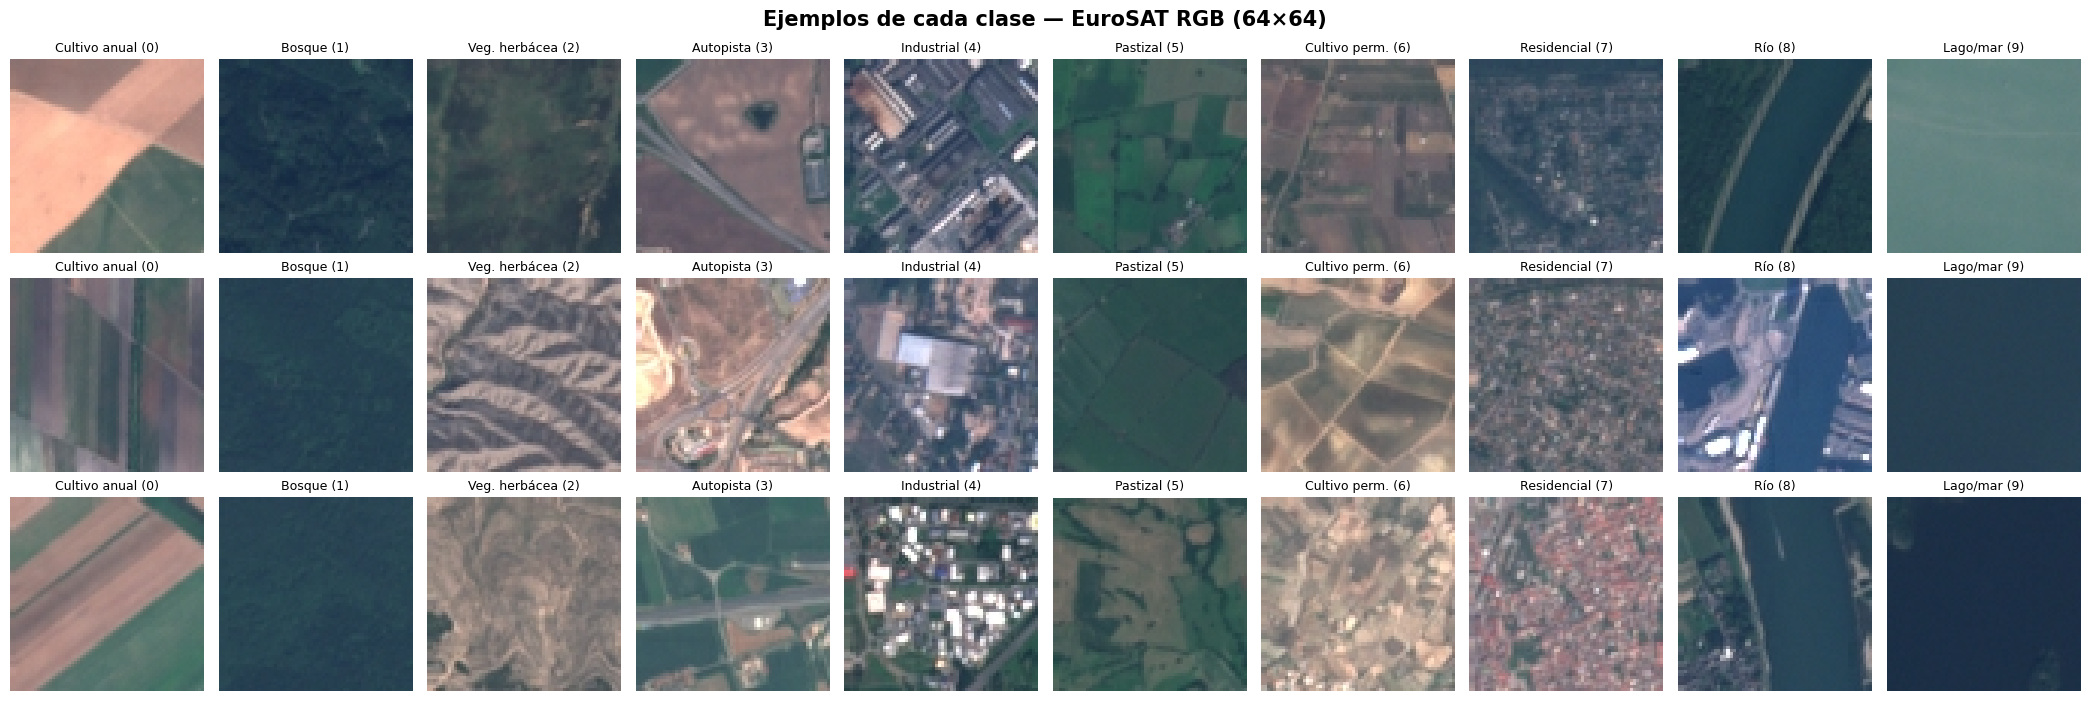

In [ ]:
n_por_clase = 3
fig, axes = plt.subplots(n_por_clase, NUM_CLASES, figsize=(2.1*NUM_CLASES, 2.4*n_por_clase))
rng = np.random.default_rng(SEED)
for c, clase in enumerate(CLASES):
    indices = rng.choice(np.where(y == c)[0], n_por_clase, replace=False)
    for f, i in enumerate(indices):
        ax = axes[f, c]
        ax.imshow(X[i])
        ax.set_title(f"{clase} ({c})", fontsize=9)
        ax.axis("off")
plt.suptitle("Ejemplos de cada clase — EuroSAT RGB (64×64)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### B.6 Distribución de clases
**Qué hace este bloque:**
- Cuenta cuántas imágenes hay por clase con `np.bincount` y lo grafica en barras, anotando el conteo y el porcentaje.
- Permite ver si el dataset está **desbalanceado**. En EuroSAT las clases tienen entre 2 000 y 3 000 imágenes: el desbalance es leve, pero igual se usa estratificación en el split y se mira el F1 por clase en la evaluación.

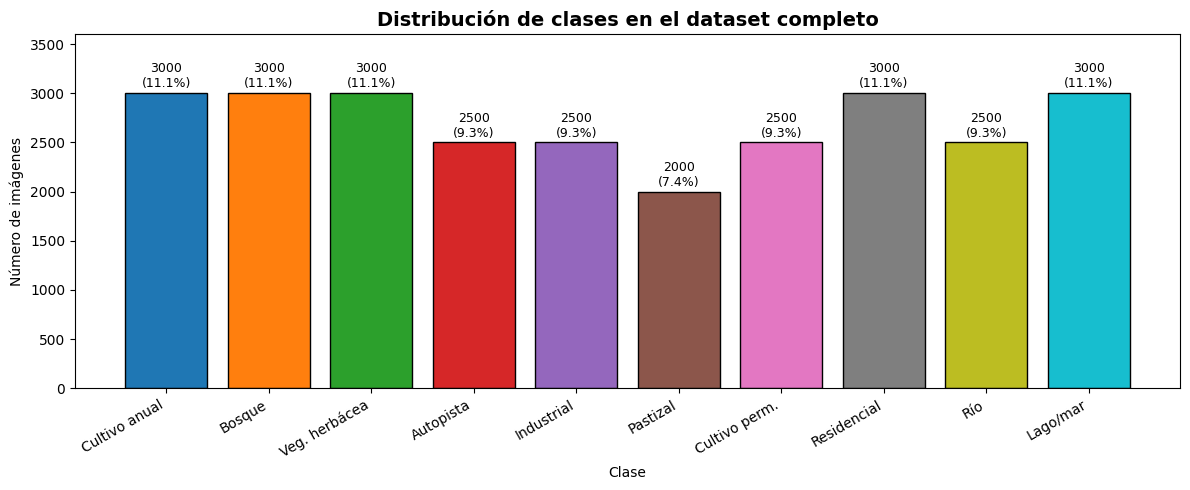

        clase  imagenes  porcentaje
Cultivo anual      3000       11.11
       Bosque      3000       11.11
Veg. herbácea      3000       11.11
    Autopista      2500        9.26
   Industrial      2500        9.26
     Pastizal      2000        7.41
Cultivo perm.      2500        9.26
  Residencial      3000       11.11
          Río      2500        9.26
     Lago/mar      3000       11.11

Razón clase mayoritaria / minoritaria: 1.50


In [ ]:
conteos = np.bincount(y, minlength=NUM_CLASES)
porcentajes = conteos / conteos.sum() * 100

plt.figure(figsize=(12, 5))
barras = plt.bar(CLASES, conteos, color=sns.color_palette("tab10", NUM_CLASES), edgecolor="black")
for b, n, p in zip(barras, conteos, porcentajes):
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 30, f"{n}\n({p:.1f}%)",
             ha="center", va="bottom", fontsize=9)
plt.title("Distribución de clases en el dataset completo", fontsize=14, fontweight="bold")
plt.xlabel("Clase"); plt.ylabel("Número de imágenes")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, conteos.max() * 1.2)
plt.tight_layout(); plt.show()

print(pd.DataFrame({"clase": CLASES, "imagenes": conteos, "porcentaje": porcentajes.round(2)}).to_string(index=False))
print(f"\nRazón clase mayoritaria / minoritaria: {conteos.max()/conteos.min():.2f}")

### B.6b Color medio por clase (exploración adicional)
**Qué hace este bloque:**
- Calcula el valor medio de los canales R, G y B de todas las imágenes de cada clase y lo grafica como barras agrupadas, junto con un parche del color promedio.
- Ayuda a entender qué información de color puede usar la red: *Bosque* y *Lago/mar* son las clases más oscuras (con poco rojo), *Industrial* es la más clara, y *Cultivo anual* y *Cultivo permanente* tienen un color promedio casi idéntico, lo que anticipa que la red tendrá que distinguirlas por la **textura** (forma y tamaño de las parcelas) y no por el color. En casi todas las clases el canal azul es alto por el efecto de la atmósfera (bruma) en las imágenes satelitales.

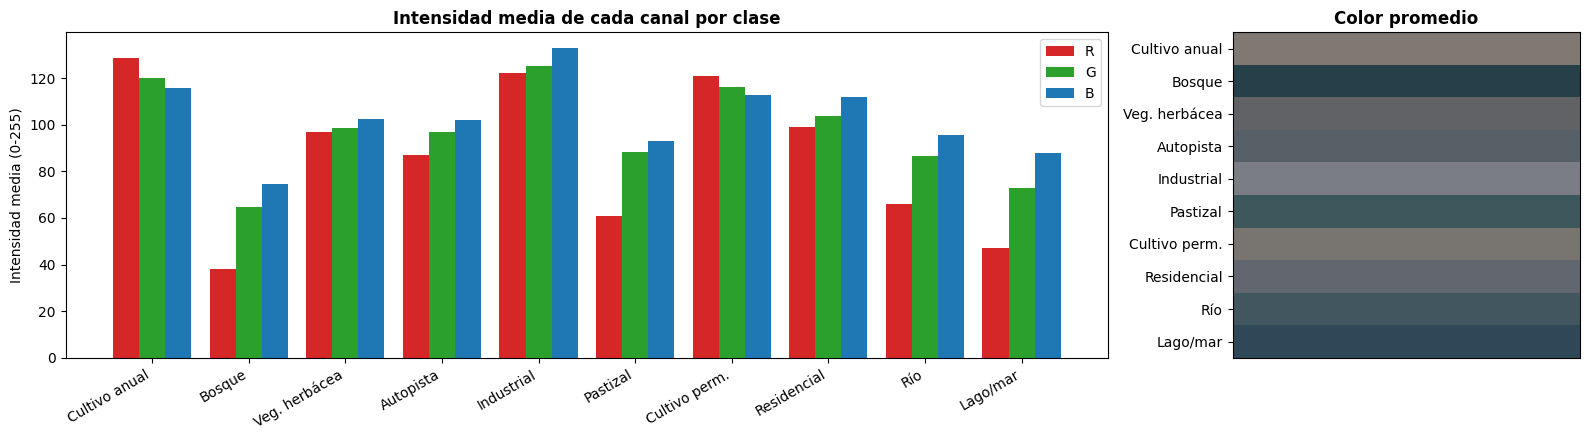

In [ ]:
color_medio = np.array([X[y == c].reshape(-1, 3).mean(axis=0) for c in range(NUM_CLASES)])

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
ancho = 0.27
pos = np.arange(NUM_CLASES)
for k, (canal, col) in enumerate(zip("RGB", ["tab:red", "tab:green", "tab:blue"])):
    ax[0].bar(pos + (k-1)*ancho, color_medio[:, k], ancho, color=col, label=canal)
ax[0].set_xticks(pos); ax[0].set_xticklabels(CLASES, rotation=30, ha="right")
ax[0].set_ylabel("Intensidad media (0-255)"); ax[0].legend()
ax[0].set_title("Intensidad media de cada canal por clase", fontweight="bold")

ax[1].imshow(color_medio[:, None, :].astype(np.uint8), aspect="auto")
ax[1].set_yticks(range(NUM_CLASES)); ax[1].set_yticklabels(CLASES); ax[1].set_xticks([])
ax[1].set_title("Color promedio", fontweight="bold")
plt.tight_layout(); plt.show()

### B.7 Split estratificado: train / validación / test
**Qué hace este bloque:**
- Como EuroSAT **no trae un conjunto de test oficial**, primero se separa un **15 % como test** (estratificado). Este conjunto no se toca hasta la Sección F.
- Del 85 % restante se separa el **10 % como validación** (estratificado), tal como pide la consigna. La validación se usa para monitorear el entrenamiento, activar los callbacks y comparar modelos.
- `stratify=y` mantiene la misma proporción de cada clase en los tres conjuntos; sin estratificar, por azar una clase podría quedar sub-representada en validación o test y las métricas serían engañosas.
- `random_state=SEED` hace que la división sea siempre la misma.

In [ ]:
# 1) Separar test (15 %) del total
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)

# 2) Separar validación (10 % del train) con estratificación
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.10, stratify=y_trainval, random_state=SEED)

del X_trainval, y_trainval   # liberar memoria

# Verificación de la estratificación: proporción de cada clase en cada conjunto
proporciones = pd.DataFrame({
    "train (%)": np.bincount(y_train) / len(y_train) * 100,
    "val (%)"  : np.bincount(y_val)   / len(y_val)   * 100,
    "test (%)" : np.bincount(y_test)  / len(y_test)  * 100,
}, index=CLASES).round(2)
print(proporciones)

               train (%)  val (%)  test (%)
Cultivo anual      11.11    11.11     11.11
Bosque             11.11    11.11     11.11
Veg. herbácea      11.11    11.11     11.11
Autopista           9.26     9.28      9.26
Industrial          9.26     9.24      9.26
Pastizal            7.41     7.41      7.41
Cultivo perm.       9.26     9.28      9.26
Residencial        11.11    11.11     11.11
Río                 9.26     9.24      9.26
Lago/mar           11.11    11.11     11.11


### B.8 Normalización a [0, 1], reshape y resumen numérico
**Qué hace este bloque:**
- Convierte los píxeles de enteros 0–255 a `float32` y los divide entre 255 para dejarlos en el rango **[0, 1]**. Con valores pequeños y en la misma escala, los gradientes son más estables y la red converge más rápido.
- **Reshape:** las imágenes ya tienen la forma `(alto, ancho, canales) = (64, 64, 3)` que espera `Conv2D`, así que no hace falta agregar un eje de canal (eso solo sería necesario con imágenes en escala de grises como MNIST). Se verifica con `assert`.
- Muestra el resumen final: cantidad de imágenes y forma de cada conjunto.

In [ ]:
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32")   / 255.0
X_test  = X_test.astype("float32")  / 255.0
del X   # el arreglo original ya no se necesita

# Comprobación del formato que espera Conv2D: (N, alto, ancho, canales)
for nombre, arr in [("train", X_train), ("val", X_val), ("test", X_test)]:
    assert arr.ndim == 4 and arr.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), nombre

print(f"Rango de píxeles en train: [{X_train.min():.1f}, {X_train.max():.1f}]\n")
resumen = pd.DataFrame({
    "conjunto": ["train", "validación", "test", "TOTAL"],
    "imágenes": [len(X_train), len(X_val), len(X_test), len(X_train)+len(X_val)+len(X_test)],
    "shape X":  [str(X_train.shape), str(X_val.shape), str(X_test.shape), "-"],
    "shape y":  [str(y_train.shape), str(y_val.shape), str(y_test.shape), "-"],
})
print(resumen.to_string(index=False))

Rango de píxeles en train: [0.0, 1.0]

  conjunto  imágenes            shape X  shape y
     train     20655 (20655, 64, 64, 3) (20655,)
validación      2295  (2295, 64, 64, 3)  (2295,)
      test      4050  (4050, 64, 64, 3)  (4050,)
     TOTAL     27000                  -        -


## SECCIÓN C — CNN Base (sin regularización)

### C.1 Diseño de la arquitectura base
**Qué hace este bloque:**
- Define una CNN secuencial con **3 bloques convolucionales** (`Conv2D` + `MaxPooling2D`) con 32, 64 y 128 filtros de 3×3:
  - `Conv2D` aprende filtros que detectan patrones locales: bordes y colores en la primera capa, texturas (surcos de cultivo, techos, copas de árboles) en las siguientes.
  - `padding='same'` agrega ceros en el borde para que la salida conserve el alto y ancho de la entrada; así no se pierde información de los bordes y el tamaño solo se reduce en el pooling.
  - `MaxPooling2D` (2×2) reduce el tamaño a la mitad (64→32→16→8), lo que baja el costo y da cierta invariancia a pequeños desplazamientos.
- `Flatten` aplana el mapa final de 8×8×128 en un vector de 8 192 valores, seguido de una capa `Dense(128)` con ReLU y la capa de salida `Dense(10, softmax)` que entrega una probabilidad por clase.
- Esta red **no tiene ninguna regularización** (ni dropout ni augmentation): es el punto de referencia para medir el overfitting.

In [ ]:
def crear_cnn_base():
    modelo = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        # Bloque convolucional 1
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloque convolucional 2
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloque convolucional 3
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Clasificador
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ], name="CNN_Base")
    return modelo

keras.utils.set_random_seed(SEED)
cnn_base = crear_cnn_base()

### C.2 Compilación (Adam + sparse_categorical_crossentropy)
**Qué hace este bloque:**
- **Adam** (tasa de aprendizaje 0.001) ajusta automáticamente el paso de cada peso combinando *momentum* y escalado adaptativo; es el optimizador estándar para empezar.
- **sparse_categorical_crossentropy** es la pérdida para clasificación multiclase cuando las etiquetas son enteros (0, 1, …, 9), como las que entrega `image_dataset_from_directory`. Si las etiquetas estuvieran en *one-hot* se usaría `categorical_crossentropy`.
- Se monitorea la métrica `accuracy`.

In [ ]:
cnn_base.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])

### C.3 Resumen del modelo y conteo de parámetros
**Qué hace este bloque:**
- `model.summary()` lista cada capa, su forma de salida y su número de parámetros.
- Luego se suman los parámetros por tipo de capa para responder **dónde se concentran**. En esta arquitectura la gran mayoría está en la capa `Dense` posterior al `Flatten` (8 192 × 128 ≈ 1,05 millones de pesos), mientras que las convoluciones tienen pocos parámetros porque comparten pesos en toda la imagen. Esa capa densa es una de las causas del overfitting y la razón de usar *Global Average Pooling* en la CNN mejorada.

In [ ]:
cnn_base.summary()

def contar_parametros(modelo):
    filas = []
    for capa in modelo.layers:
        n = capa.count_params()
        if n > 0:
            filas.append((capa.name, capa.__class__.__name__, n))
    df = pd.DataFrame(filas, columns=["capa", "tipo", "parámetros"])
    total = df["parámetros"].sum()
    por_tipo = df.groupby("tipo")["parámetros"].sum().sort_values(ascending=False)
    print(f"\nTotal de parámetros: {total:,}")
    for tipo, n in por_tipo.items():
        print(f"  {tipo:<20s}: {n:>12,} ({n/total*100:.1f} %)")
    return total

params_base = contar_parametros(cnn_base)

Model: "CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)


Total de parámetros: 1,143,242
  Dense               :    1,049,994 (91.8 %)
  Conv2D              :       93,248 (8.2 %)


### C.4 Entrenamiento de la CNN base (20 épocas)
**Qué hace este bloque:**
- `fit` entrena con `X_train` en lotes de 32 imágenes durante 20 épocas.
- `validation_data=(X_val, y_val)` evalúa en validación al final de cada época **sin entrenar con esos datos**, lo que permite detectar overfitting.
- El objeto `historia_base` guarda accuracy y loss de train y validación por época.

In [ ]:
inicio = time.time()
historia_base = cnn_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_BASE,
    batch_size=BATCH_SIZE,
    verbose=2)
print(f"\nTiempo de entrenamiento: {time.time()-inicio:.1f} s")

Epoch 1/20
646/646 - 19s - 29ms/step - accuracy: 0.5710 - loss: 1.1376 - val_accuracy: 0.7102 - val_loss: 0.8086
Epoch 2/20
646/646 - 5s - 7ms/step - accuracy: 0.7552 - loss: 0.6829 - val_accuracy: 0.8052 - val_loss: 0.5430
Epoch 3/20
646/646 - 4s - 7ms/step - accuracy: 0.8106 - loss: 0.5290 - val_accuracy: 0.8109 - val_loss: 0.5235
Epoch 4/20
646/646 - 4s - 7ms/step - accuracy: 0.8411 - loss: 0.4488 - val_accuracy: 0.8048 - val_loss: 0.5523
Epoch 5/20
646/646 - 4s - 7ms/step - accuracy: 0.8679 - loss: 0.3731 - val_accuracy: 0.8209 - val_loss: 0.5293
Epoch 6/20
646/646 - 5s - 7ms/step - accuracy: 0.8922 - loss: 0.3103 - val_accuracy: 0.8314 - val_loss: 0.4991
Epoch 7/20
646/646 - 5s - 7ms/step - accuracy: 0.9062 - loss: 0.2722 - val_accuracy: 0.8227 - val_loss: 0.5454
Epoch 8/20
646/646 - 4s - 7ms/step - accuracy: 0.9221 - loss: 0.2179 - val_accuracy: 0.8414 - val_loss: 0.5579
Epoch 9/20
646/646 - 4s - 7ms/step - accuracy: 0.9374 - loss: 0.1775 - val_accuracy: 0.7926 - val_loss: 0.9172

### C.5 Curvas de aprendizaje (accuracy y loss, train vs val)
**Qué hace este bloque:**
- Define una función reutilizable `graficar_historia` que dibuja dos gráficos lado a lado: accuracy y loss por época, con train y validación superpuestos.
- Se marca la época con menor `val_loss`. La forma de estas curvas es la base del diagnóstico de overfitting.

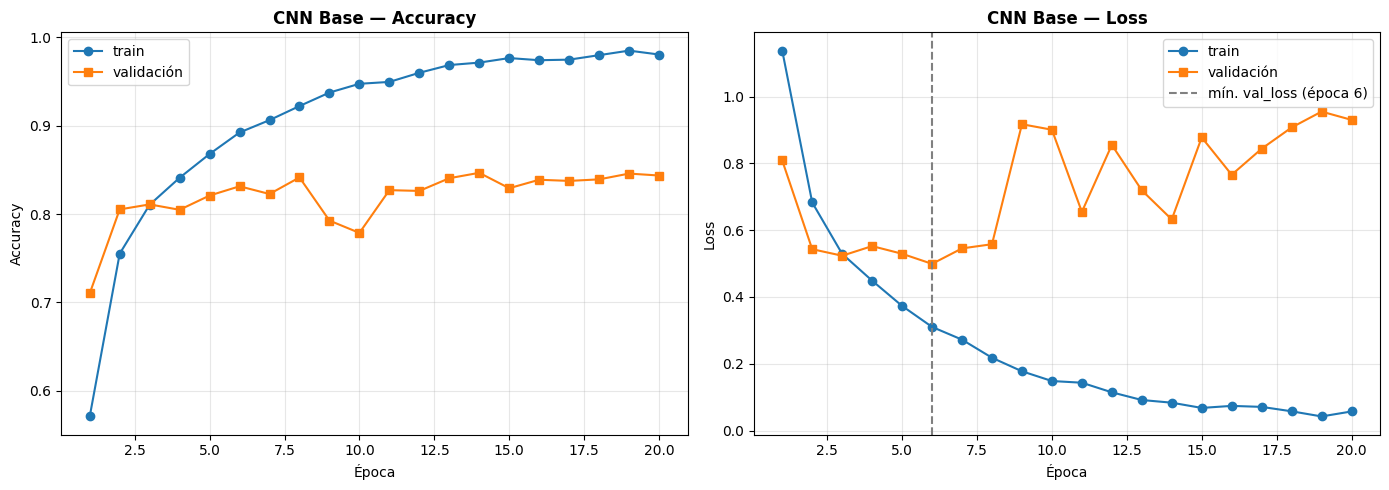

In [ ]:
def graficar_historia(historia, titulo):
    h = historia.history
    epocas = range(1, len(h["loss"]) + 1)
    mejor = int(np.argmin(h["val_loss"])) + 1
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    ax[0].plot(epocas, h["accuracy"], "o-", label="train")
    ax[0].plot(epocas, h["val_accuracy"], "s-", label="validación")
    ax[0].set_title(f"{titulo} — Accuracy", fontweight="bold")
    ax[0].set_xlabel("Época"); ax[0].set_ylabel("Accuracy"); ax[0].grid(alpha=.3); ax[0].legend()

    ax[1].plot(epocas, h["loss"], "o-", label="train")
    ax[1].plot(epocas, h["val_loss"], "s-", label="validación")
    ax[1].axvline(mejor, color="gray", ls="--", label=f"mín. val_loss (época {mejor})")
    ax[1].set_title(f"{titulo} — Loss", fontweight="bold")
    ax[1].set_xlabel("Época"); ax[1].set_ylabel("Loss"); ax[1].grid(alpha=.3); ax[1].legend()
    plt.tight_layout(); plt.show()

graficar_historia(historia_base, "CNN Base")

### C.6 Diagnóstico de overfitting (cálculo)
**Qué hace este bloque:**
- Calcula los indicadores que se usan para argumentar el diagnóstico: accuracy final de train y validación, la **brecha** entre ambas, la época donde `val_loss` fue mínima y cuánto subió `val_loss` desde ese mínimo hasta la última época.
- Regla práctica: si el accuracy de train sigue subiendo hacia ~100 % mientras el de validación se estanca y `val_loss` sube, el modelo está **memorizando** el entrenamiento (overfitting).

In [ ]:
def diagnostico(historia, nombre):
    h = historia.history
    tr, va = h["accuracy"][-1], h["val_accuracy"][-1]
    ep_min = int(np.argmin(h["val_loss"])) + 1
    vl_min, vl_fin = min(h["val_loss"]), h["val_loss"][-1]
    print(f"===== Diagnóstico {nombre} =====")
    print(f"Accuracy train (última época)  : {tr:.4f}")
    print(f"Accuracy val   (última época)  : {va:.4f}")
    print(f"Mejor accuracy val             : {max(h['val_accuracy']):.4f}")
    print(f"Brecha train - val             : {(tr-va)*100:.2f} puntos porcentuales")
    print(f"Loss train (última época)      : {h['loss'][-1]:.4f}")
    print(f"Época con mínima val_loss      : {ep_min} (val_loss = {vl_min:.4f})")
    print(f"val_loss en la última época    : {vl_fin:.4f} ({(vl_fin/vl_min-1)*100:+.1f} % vs. mínimo)")
    return {"train_acc": tr, "val_acc": va, "best_val_acc": max(h["val_accuracy"]),
            "brecha": tr - va, "epoca_min_val_loss": ep_min, "min_val_loss": vl_min,
            "val_loss_final": vl_fin, "train_loss_final": h["loss"][-1]}

diag_base = diagnostico(historia_base, "CNN Base")

===== Diagnóstico CNN Base =====
Accuracy train (última época)  : 0.9804
Accuracy val   (última época)  : 0.8436
Mejor accuracy val             : 0.8466
Brecha train - val             : 13.69 puntos porcentuales
Loss train (última época)      : 0.0572
Época con mínima val_loss      : 6 (val_loss = 0.4991)
val_loss en la última época    : 0.9302 (+86.4 % vs. mínimo)


### C.6 Diagnóstico de overfitting (párrafo)

La CNN base alcanza un accuracy de entrenamiento de **98,04 %** en la última época (la 20), mientras que en validación se queda en **84,36 %**: una brecha de **13,69 puntos porcentuales**. En las curvas, la pérdida de validación toca su mínimo en la época **6** (0,4991) y desde entonces sube, con oscilaciones, hasta **0,9302** en la época 20 (**+86,4 %** sobre su mínimo), mientras que la pérdida de entrenamiento sigue cayendo hasta 0,0572. El accuracy de validación, en cambio, queda estancado entre ≈78 % y ≈85 % desde la época 2 (su máximo, 84,66 %, ocurre en la época 14). Este patrón (train mejora, validación se estanca y su pérdida empeora) es la señal clásica de **overfitting**: la red memoriza las imágenes de entrenamiento en lugar de aprender rasgos generales de cada tipo de suelo. Es la `val_loss`, más que el accuracy de validación, la que delata el problema: el modelo sigue acertando casi igual, pero con predicciones cada vez más seguras cuando se equivoca. Las causas probables son: (1) la capa `Dense` posterior al `Flatten` concentra el **91,8 %** de los 1 143 242 parámetros (1 049 994) y tiene capacidad de sobra para memorizar; (2) la ausencia total de regularización (sin dropout, sin L2, sin data augmentation); y (3) que la red ve exactamente las mismas imágenes en cada época. Esto justifica la CNN mejorada de la Sección D.

## SECCIÓN D — CNN Mejorada (con regularización)

Se aplican **5 técnicas** de regularización (la consigna pide al menos 3):

| Técnica | Dónde | Por qué ayuda |
|---|---|---|
| **Data Augmentation** | Primera capa del modelo | Genera variaciones aleatorias (giros, rotaciones, zoom, contraste) en cada época: el modelo nunca ve la misma imagen dos veces y aprende invariancias reales. |
| **Batch Normalization** | Después de cada `Conv2D`, antes de ReLU | Normaliza las activaciones de cada lote (media 0, varianza 1): estabiliza y acelera el entrenamiento y aporta una ligera regularización. |
| **Dropout** | 0.1 tras cada bloque y 0.3 antes de la salida | Apaga neuronas al azar en entrenamiento, obligando a no depender de unas pocas. |
| **Global Average Pooling (GAP)** | En lugar de `Flatten` | Promedia cada mapa de características en un solo valor: elimina la gran capa densa y reduce drásticamente los parámetros. |
| **Regularización L2** | En los kernels de `Conv2D` y `Dense` | Penaliza pesos grandes en la función de pérdida, favoreciendo modelos más simples. |

### D.1 Data Augmentation y visualización de 4 variaciones
**Qué hace este bloque:**
- Crea un bloque `Sequential` con capas de preprocesamiento de Keras que **solo actúan durante el entrenamiento** (en `predict`/`evaluate` se desactivan solas):
  - `RandomFlip("horizontal_and_vertical")`: espejo horizontal y vertical. En una imagen satelital **no existe “arriba” ni “abajo”**: un bosque o un río reflejados siguen siendo la misma clase. (En fotos normales el giro vertical no tendría sentido; aquí sí.)
  - `RandomRotation(0.25, fill_mode="reflect")`: rota hasta ±90°; el satélite puede captar una autopista o un río en cualquier orientación. El relleno por reflejo evita esquinas negras artificiales.
  - `RandomZoom(0.1)`: acerca/aleja hasta 10 %; simula pequeñas diferencias de escala.
  - `RandomContrast(0.1)`: varía el contraste; simula distinta iluminación, estación del año o bruma atmosférica.
- Se muestran la imagen original y **4 variaciones** generadas con `training=True`.

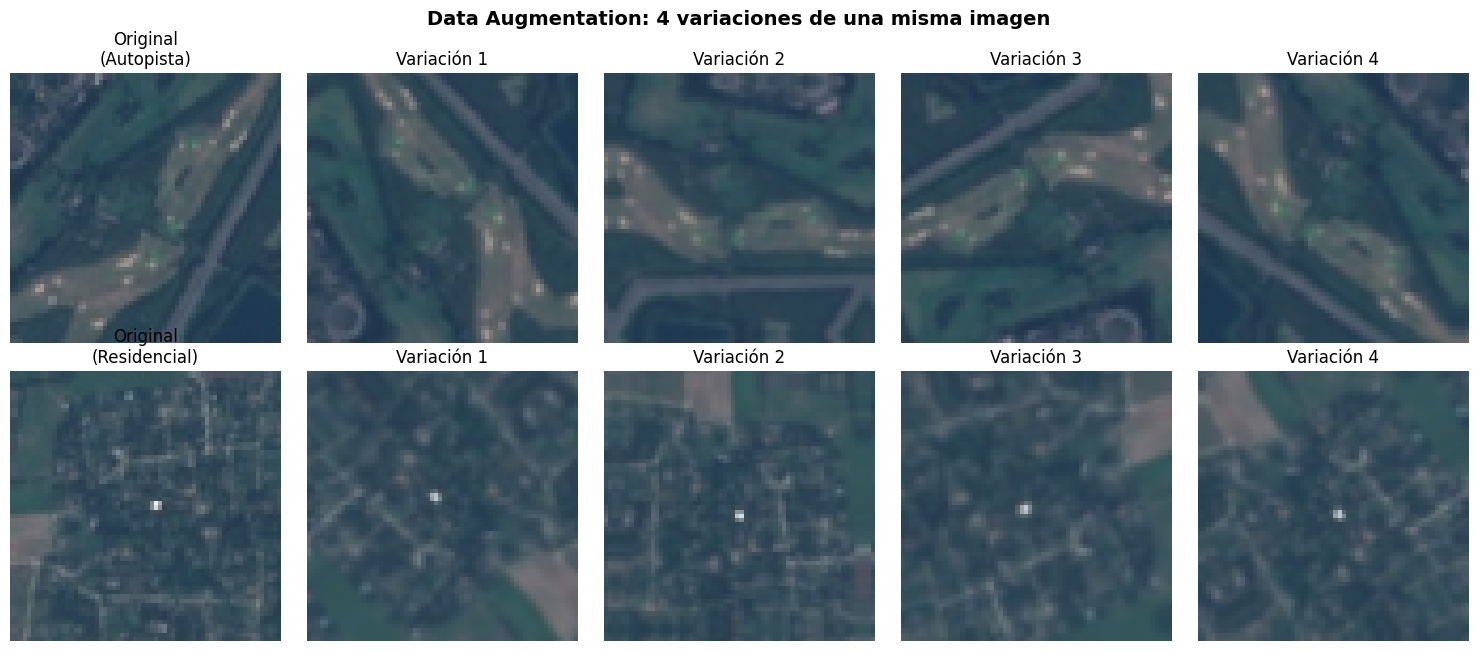

In [ ]:
def crear_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
        layers.RandomContrast(0.1),
    ], name="data_augmentation")

aug_demo = crear_augmentation()
ejemplos = [int(np.where(y_train == CLASES.index("Autopista"))[0][0]),
            int(np.where(y_train == CLASES.index("Residencial"))[0][0])]

fig, axes = plt.subplots(len(ejemplos), 5, figsize=(15, 3.3*len(ejemplos)))
for fila, idx in enumerate(ejemplos):
    imagen = X_train[idx]
    axes[fila, 0].imshow(imagen); axes[fila, 0].set_title(f"Original\n({CLASES[y_train[idx]]})")
    for i in range(1, 5):
        aumentada = aug_demo(tf.expand_dims(imagen, 0), training=True)[0].numpy()
        axes[fila, i].imshow(np.clip(aumentada, 0, 1))
        axes[fila, i].set_title(f"Variación {i}")
    for a in axes[fila]: a.axis("off")
plt.suptitle("Data Augmentation: 4 variaciones de una misma imagen", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### D.2 Arquitectura de la CNN mejorada
**Qué hace este bloque:**
- `bloque_conv` encapsula un bloque: `Conv2D` (sin sesgo, con L2) → `BatchNormalization` → `ReLU` → `MaxPooling2D` → `Dropout(0.1)`.
  - `use_bias=False` porque BatchNormalization ya incluye un desplazamiento (β) que cumple la función del sesgo.
  - BN se coloca **antes de la activación** para normalizar la entrada de ReLU y evitar que muchas neuronas queden “muertas” (siempre en 0) o con activaciones descontroladas.
  - El Dropout de los bloques es moderado (0.1) porque ya se combina con augmentation, BN y L2; valores muy altos harían que la red **subentrene**.
- La red usa **4 bloques** (32, 64, 128 y 256 filtros); el 4.º bloque permite detectar patrones más complejos ahora que la regularización controla el overfitting. El tamaño baja 64→32→16→8→4.
- `GlobalAveragePooling2D` reemplaza a `Flatten`: convierte el mapa 4×4×256 en un vector de 256 valores (promedio de cada filtro), en vez de 4 096.
- Clasificador: `Dense(128)` con L2 → `Dropout(0.3)` → `Dense(10, softmax)`.
- Se usa la API funcional de Keras y la función recibe el optimizador como parámetro para reutilizarla en la Sección E con SGD, Adam y RMSprop.

In [ ]:
L2 = 1e-4   # intensidad de la regularización L2

def bloque_conv(x, filtros):
    x = layers.Conv2D(filtros, (3, 3), padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(L2))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.1)(x)
    return x

def crear_cnn_mejorada(optimizador=None, nombre="CNN_Mejorada"):
    entradas = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = crear_augmentation()(entradas)               # 1) Data Augmentation
    for filtros in [32, 64, 128, 256]:               # 2) BN + 3) Dropout + 5) L2
        x = bloque_conv(x, filtros)
    x = layers.GlobalAveragePooling2D()(x)           # 4) GAP en lugar de Flatten
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(L2))(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(NUM_CLASES, activation="softmax")(x)

    modelo = keras.Model(entradas, salidas, name=nombre)
    modelo.compile(optimizer=optimizador or keras.optimizers.Adam(learning_rate=1e-3),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

keras.utils.set_random_seed(SEED)
cnn_mejorada = crear_cnn_mejorada()
cnn_mejorada.summary()
params_mejorada = contar_parametros(cnn_mejorada)
print(f"\nReducción de parámetros vs. CNN Base: {(1 - params_mejorada/params_base)*100:.1f} %")

Model: "CNN_Mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 424,042 (1.62 MB)

 Trainable params: 423,082 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


Total de parámetros: 424,042
  Conv2D              :      387,936 (91.5 %)
  Dense               :       34,186 (8.1 %)
  BatchNormalization  :        1,920 (0.5 %)

Reducción de parámetros vs. CNN Base: 62.9 %


### D.3 Entrenamiento con callbacks
**Qué hace este bloque:**
- **EarlyStopping** (`monitor='val_loss'`, `patience=8`, `restore_best_weights=True`): si la pérdida de validación no mejora durante 8 épocas seguidas, detiene el entrenamiento y **restaura los pesos de la mejor época**. Evita seguir entrenando cuando ya empezó el overfitting. Se usa paciencia 8 (≥ 5) porque con augmentation la validación oscila de una época a otra.
- **ReduceLROnPlateau** (`factor=0.5`, `patience=3`): si `val_loss` se estanca 3 épocas, reduce la tasa de aprendizaje a la mitad. Pasos más pequeños permiten afinar los pesos cerca de un mínimo.
- Como ReduceLROnPlateau tiene menor paciencia (3) que EarlyStopping (8), primero se intenta bajar el *learning rate* y solo si eso no ayuda se detiene el entrenamiento.
- Se fija un máximo de 40 épocas.

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                      min_lr=1e-5, verbose=1),
]

inicio = time.time()
historia_mejorada = cnn_mejorada.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_MEJORADA,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=2)
print(f"\nTiempo de entrenamiento: {time.time()-inicio:.1f} s")
print(f"Épocas ejecutadas: {len(historia_mejorada.history['loss'])}")

Epoch 1/40
646/646 - 19s - 29ms/step - accuracy: 0.6400 - loss: 1.0761 - val_accuracy: 0.5268 - val_loss: 1.4696 - learning_rate: 0.0010
Epoch 2/40
646/646 - 17s - 26ms/step - accuracy: 0.7333 - loss: 0.8184 - val_accuracy: 0.7673 - val_loss: 0.7185 - learning_rate: 0.0010
Epoch 3/40
646/646 - 11s - 18ms/step - accuracy: 0.7655 - loss: 0.7363 - val_accuracy: 0.7935 - val_loss: 0.6506 - learning_rate: 0.0010
Epoch 4/40
646/646 - 12s - 18ms/step - accuracy: 0.7916 - loss: 0.6673 - val_accuracy: 0.7150 - val_loss: 0.8425 - learning_rate: 0.0010
Epoch 5/40
646/646 - 12s - 18ms/step - accuracy: 0.8149 - loss: 0.6145 - val_accuracy: 0.6941 - val_loss: 0.9725 - learning_rate: 0.0010
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
646/646 - 21s - 32ms/step - accuracy: 0.8315 - loss: 0.5734 - val_accuracy: 0.7582 - val_loss: 0.8214 - learning_rate: 0.0010
Epoch 7/40
646/646 - 11s - 18ms/step - accuracy: 0.8687 - loss: 0.4642 - val_accuracy: 0.6514 - val_l

### D.4 Curvas de aprendizaje de la CNN mejorada
**Qué hace este bloque:** reutiliza `graficar_historia` y además grafica cómo cambió la tasa de aprendizaje por efecto de ReduceLROnPlateau (Keras la guarda en `history['learning_rate']` o `history['lr']` según la versión).

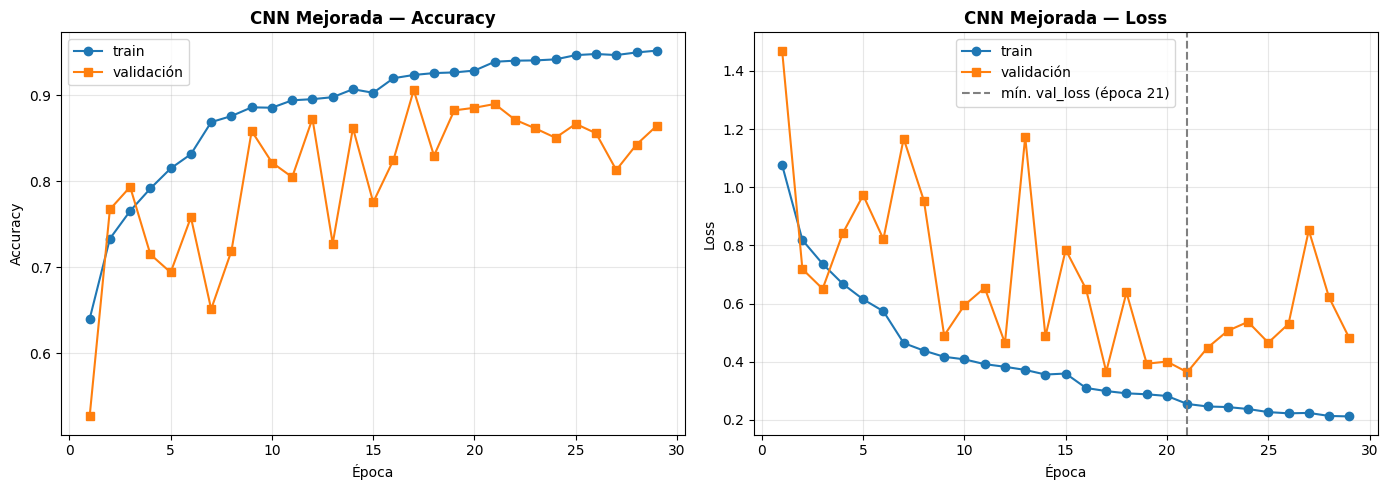

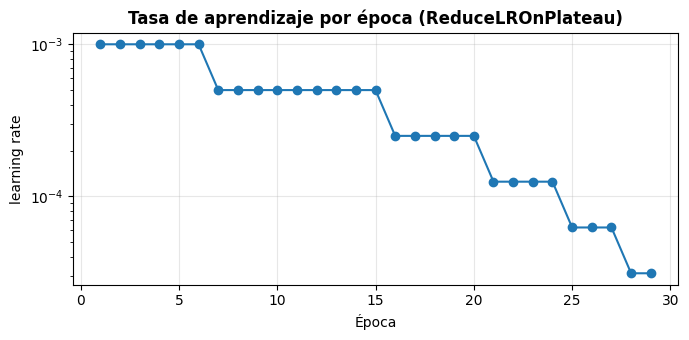

Reducciones del learning rate: 5


In [ ]:
graficar_historia(historia_mejorada, "CNN Mejorada")

clave_lr = "learning_rate" if "learning_rate" in historia_mejorada.history else "lr"
if clave_lr in historia_mejorada.history:
    lrs = historia_mejorada.history[clave_lr]
    plt.figure(figsize=(7, 3.5))
    plt.plot(range(1, len(lrs) + 1), lrs, "o-")
    plt.yscale("log"); plt.grid(alpha=.3)
    plt.title("Tasa de aprendizaje por época (ReduceLROnPlateau)", fontweight="bold")
    plt.xlabel("Época"); plt.ylabel("learning rate")
    plt.tight_layout(); plt.show()
    print("Reducciones del learning rate:", int(np.sum(np.diff(lrs) < 0)))

### D.5 Comparación cuantitativa CNN Base vs. CNN Mejorada
**Qué hace este bloque:**
- Ejecuta el mismo diagnóstico de la Sección C sobre la CNN mejorada.
- Evalúa ambos modelos sobre **validación** con `evaluate` (la CNN mejorada ya tiene restaurados sus mejores pesos).
- Arma una tabla comparativa y un gráfico de barras con accuracy de validación y brecha train-val. El test se reserva para la Sección F.

===== Diagnóstico CNN Mejorada =====
Accuracy train (última época)  : 0.9518
Accuracy val   (última época)  : 0.8645
Mejor accuracy val             : 0.9059
Brecha train - val             : 8.73 puntos porcentuales
Loss train (última época)      : 0.2119
Época con mínima val_loss      : 21 (val_loss = 0.3639)
val_loss en la última época    : 0.4812 (+32.2 % vs. mínimo)


,Parámetros,Épocas entrenadas,Acc. train (final),Acc. val (pesos finales),Brecha train-val (pp),Mín. val_loss
CNN Base,1143242,20,0.9804,0.8436,13.6868,0.4991
CNN Mejorada,424042,29,0.9518,0.8898,8.7291,0.3639


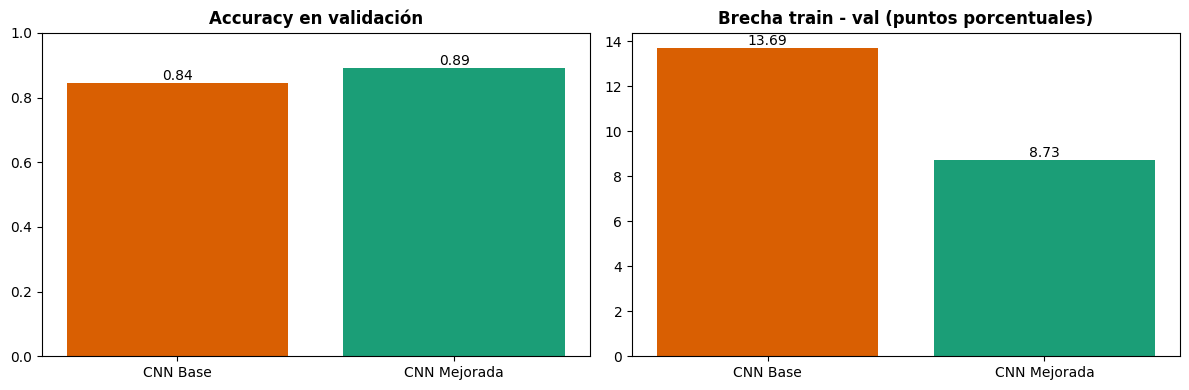

In [ ]:
diag_mejorada = diagnostico(historia_mejorada, "CNN Mejorada")

_, acc_val_base = cnn_base.evaluate(X_val, y_val, verbose=0)
_, acc_val_mej  = cnn_mejorada.evaluate(X_val, y_val, verbose=0)

comparacion = pd.DataFrame({
    "Parámetros":               [params_base, params_mejorada],
    "Épocas entrenadas":        [len(historia_base.history["loss"]), len(historia_mejorada.history["loss"])],
    "Acc. train (final)":       [diag_base["train_acc"], diag_mejorada["train_acc"]],
    "Acc. val (pesos finales)": [acc_val_base, acc_val_mej],
    "Brecha train-val (pp)":    [diag_base["brecha"]*100, diag_mejorada["brecha"]*100],
    "Mín. val_loss":            [diag_base["min_val_loss"], diag_mejorada["min_val_loss"]],
}, index=["CNN Base", "CNN Mejorada"])
display(comparacion.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colores = ["#d95f02", "#1b9e77"]
ax[0].bar(comparacion.index, comparacion["Acc. val (pesos finales)"], color=colores)
ax[0].set_title("Accuracy en validación", fontweight="bold"); ax[0].set_ylim(0, 1)
ax[1].bar(comparacion.index, comparacion["Brecha train-val (pp)"], color=colores)
ax[1].set_title("Brecha train - val (puntos porcentuales)", fontweight="bold")
for a in ax:
    for p in a.patches:
        a.annotate(f"{p.get_height():.2f}", (p.get_x()+p.get_width()/2, p.get_height()),
                   ha="center", va="bottom")
plt.tight_layout(); plt.show()

### D.6 Comparación con la CNN Base (párrafo)

La CNN mejorada **sí mejoró** el desempeño y lo hizo con un modelo mucho más pequeño. Con los pesos restaurados por EarlyStopping (época 21), el accuracy en validación fue **88,98 %** frente a **84,36 %** de la CNN base (**+4,62 puntos**; **+4,32** si se compara con la mejor época de la base, 84,66 %), y en test fue **90,12 %** frente a **83,88 %** (**+6,24 puntos**). Una precisión importante: la CNN mejorada se evalúa con sus *mejores* pesos y la base con los de su *última* época; los pesos de la última época de la mejorada (la 29) dieron 86,45 % en validación, de modo que `restore_best_weights` aporta ≈ 2,5 puntos de esa ventaja y la mejora “a igualdad de criterio” sería de ≈ 2,1 puntos. El **overfitting se redujo**: la brecha train–val bajó de **13,69 pp** a **8,73 pp** (medida en la última época; con la época 21 que se conserva, train 93,89 % frente a val 88,98 % da ≈ 4,91 pp) y la `val_loss` final quedó **+32,2 %** por encima de su mínimo (0,3639 en la época 21), contra **+86,4 %** en la base. Sin embargo, **no es correcto decir que ambas curvas avanzan juntas**: la validación de la CNN mejorada es muy **inestable** (por ejemplo, cae de 87,28 % a 72,77 % entre las épocas 12 y 13, con `val_loss` de 1,17, y vuelve a ≈ 81 % en la época 27). Es un comportamiento esperable al combinar data augmentation, Dropout y BatchNormalization, porque en entrenamiento la red ve imágenes deformadas y con neuronas apagadas, y en validación no. ReduceLROnPlateau redujo el *learning rate* **5 veces** (de 1e-3 a ≈ 3,1e-5) y ayudó a afinar los pesos, pero no eliminó esa oscilación. En cuanto a las técnicas: la augmentation evita que la red vea dos veces la misma imagen, BN estabiliza el entrenamiento y permitió usar 4 bloques, Dropout y L2 limitan la dependencia de pesos individuales y GAP elimina la gran capa densa, lo que reduce los parámetros en **62,9 %** (de 1 143 242 a 424 042). El costo fue más épocas (29 frente a 20) y más tiempo (≈ 375 s frente a ≈ 107 s). Como no se hizo un estudio de ablación (quitar una técnica a la vez), la mejora se atribuye al conjunto y no a cada técnica por separado.

## SECCIÓN E — Comparación de Optimizadores

### E.1 Entrenamiento de la misma arquitectura con SGD, Adam y RMSprop
**Qué hace este bloque:**
- Usa exactamente la misma arquitectura (`crear_cnn_mejorada`) y la misma semilla para los tres optimizadores, de modo que **lo único que cambia es el optimizador**:
  - **SGD con momentum 0.9** (lr = 0.01): actualiza los pesos en la dirección opuesta al gradiente; el momentum acumula la dirección de pasos anteriores para avanzar más rápido y amortiguar oscilaciones. Necesita un lr mayor que los adaptativos.
  - **Adam** (lr = 0.001): combina momentum con una tasa adaptativa por parámetro.
  - **RMSprop** (lr = 0.001): divide el gradiente por la media móvil de su magnitud al cuadrado; adapta el paso, pero sin el término de momentum de primer orden de Adam.
- Se entrenan **15 épocas sin callbacks**, para comparar a todos con el mismo número de épocas y que EarlyStopping no corte a unos antes que a otros.

In [ ]:
optimizadores = {
    "SGD (momentum 0.9)": lambda: keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9),
    "Adam":               lambda: keras.optimizers.Adam(learning_rate=1e-3),
    "RMSprop":            lambda: keras.optimizers.RMSprop(learning_rate=1e-3),
}

historias_opt = {}
for nombre, crear_opt in optimizadores.items():
    print(f"\n========== Entrenando con {nombre} ==========")
    keras.utils.set_random_seed(SEED)                 # mismos pesos iniciales para todos
    modelo = crear_cnn_mejorada(optimizador=crear_opt(), nombre="CNN_" + nombre.split()[0])
    inicio = time.time()
    h = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=EPOCHS_OPT, batch_size=BATCH_SIZE, verbose=2)
    historias_opt[nombre] = h.history
    print(f"Tiempo: {time.time()-inicio:.1f} s")


========== Entrenando con SGD (momentum 0.9) ==========
Epoch 1/15
646/646 - 13s - 21ms/step - accuracy: 0.6056 - loss: 1.1643 - val_accuracy: 0.5429 - val_loss: 1.5340
Epoch 2/15
646/646 - 10s - 16ms/step - accuracy: 0.7069 - loss: 0.8783 - val_accuracy: 0.6135 - val_loss: 1.1179
Epoch 3/15
646/646 - 10s - 16ms/step - accuracy: 0.7356 - loss: 0.7980 - val_accuracy: 0.7595 - val_loss: 0.7365
Epoch 4/15
646/646 - 11s - 16ms/step - accuracy: 0.7614 - loss: 0.7420 - val_accuracy: 0.6370 - val_loss: 1.2426
Epoch 5/15
646/646 - 10s - 16ms/step - accuracy: 0.7786 - loss: 0.6925 - val_accuracy: 0.6479 - val_loss: 1.1183
Epoch 6/15
646/646 - 10s - 16ms/step - accuracy: 0.7949 - loss: 0.6533 - val_accuracy: 0.6654 - val_loss: 1.1090
Epoch 7/15
646/646 - 10s - 16ms/step - accuracy: 0.8070 - loss: 0.6206 - val_accuracy: 0.6741 - val_loss: 1.0483
Epoch 8/15
646/646 - 10s - 16ms/step - accuracy: 0.8177 - loss: 0.5869 - val_accuracy: 0.7678 - val_loss: 0.7571
Epoch 9/15
646/646 - 21s - 32ms/step - 

### E.2 val_accuracy de los optimizadores en un mismo gráfico
**Qué hace este bloque:**
- Superpone la curva de `val_accuracy` (izquierda) y `val_loss` (derecha) de los tres optimizadores.
- Calcula una tabla con la **mejor val_accuracy**, la época en que se alcanzó y la **primera época en que cada optimizador supera el 90 % de validación** (indicador de velocidad de convergencia), además de la desviación estándar de `val_accuracy` en las últimas 5 épocas (indicador de estabilidad).

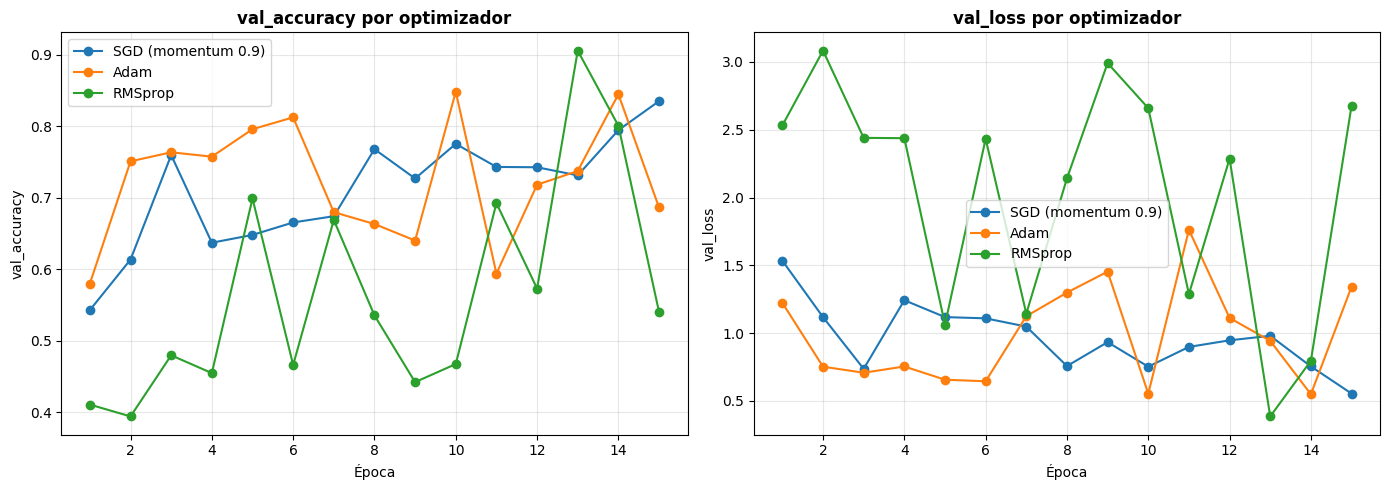

,Mejor val_acc,Época del mejor,1ª época con val_acc ≥ 0.90,val_acc época 1,val_acc final,Desv. val_acc (últ. 5),Acc. train final
Optimizador,,,,,,,
SGD (momentum 0.9),0.8349,15,NaN,0.5429,0.8349,0.0395,0.8794
Adam,0.8479,10,NaN,0.5800,0.6863,0.0809,0.8946
RMSprop,0.9054,13,13.0,0.4109,0.5403,0.1371,0.8834


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nombre, h in historias_opt.items():
    ep = range(1, len(h["val_accuracy"]) + 1)
    ax[0].plot(ep, h["val_accuracy"], "o-", label=nombre)
    ax[1].plot(ep, h["val_loss"], "o-", label=nombre)
ax[0].set_title("val_accuracy por optimizador", fontweight="bold")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("val_accuracy"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].set_title("val_loss por optimizador", fontweight="bold")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("val_loss"); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

filas = []
for nombre, h in historias_opt.items():
    va = np.array(h["val_accuracy"])
    filas.append({
        "Optimizador": nombre,
        "Mejor val_acc": va.max(),
        "Época del mejor": int(va.argmax()) + 1,
        "1ª época con val_acc ≥ 0.90": (int(np.argmax(va >= 0.90)) + 1) if (va >= 0.90).any() else None,
        "val_acc época 1": va[0],
        "val_acc final": va[-1],
        "Desv. val_acc (últ. 5)": va[-5:].std(),
        "Acc. train final": h["accuracy"][-1],
    })
tabla_opt = pd.DataFrame(filas).set_index("Optimizador")
display(tabla_opt.round(4))

In [ ]:
# E.2b — Velocidad y estabilidad con un umbral alcanzable (80 %), ya que ningún optimizador llegó a 90 %
filas = []
for nombre, h in historias_opt.items():
    va = np.array(h["val_accuracy"])
    filas.append({
        "Optimizador": nombre,
        "1ª época con val_acc ≥ 0.80": (int(np.argmax(va >= 0.80)) + 1) if (va >= 0.80).any() else None,
        "Épocas con val_acc ≥ 0.80 (de 15)": int((va >= 0.80).sum()),
        "val_acc mínima": va.min(),
        "Acc. train época 1": h["accuracy"][0],
        "Loss train final": h["loss"][-1],
    })
display(pd.DataFrame(filas).set_index("Optimizador").round(4))


,1ª época con val_acc ≥ 0.80,Épocas con val_acc ≥ 0.80 (de 15),val_acc mínima,Acc. train época 1,Loss train final
Optimizador,,,,,
SGD (momentum 0.9),15,1,0.5429,0.6056,0.4312
Adam,6,3,0.5800,0.6414,0.4136
RMSprop,13,2,0.3943,0.6353,0.4594


### E.3 Análisis de optimizadores (párrafo)

Los tres optimizadores se entrenaron 15 épocas con la misma arquitectura, la misma semilla y sin callbacks. **Solo RMSprop superó el 90 %** de `val_accuracy` (90,54 % en la época 13), y lo hizo en un pico aislado: en la época siguiente bajó a 80,04 % y en la última a 54,03 %. Por eso se usa también el umbral de **80 %** (tabla E.2b): **Adam** lo supera primero (época 6, 81,22 %), **RMSprop** en la época 13 y **SGD con momentum** solo en la 15 (83,49 %). Sobre el conjunto de entrenamiento, Adam también es el más rápido: mayor accuracy de train en la época 1 (64,14 % frente a 63,53 % de RMSprop y 60,56 % de SGD) y menor pérdida final (0,4136, frente a 0,4312 de SGD y 0,4594 de RMSprop). En el **mejor resultado** de validación el primero es RMSprop (90,54 %), seguido de Adam (84,79 %, época 10) y SGD (83,49 %, época 15), pero **ese ranking no es confiable**: RMSprop fue con diferencia el más inestable (`val_loss` entre 0,39 y 3,08; `val_accuracy` de hasta 39,43 % en la época 2; desviación de `val_accuracy` en las últimas 5 épocas de 0,137, frente a 0,081 de Adam y 0,040 de SGD), Adam tuvo caídas repetidas (59–69 % en las épocas 7 a 9, 11 y 15) y, en una ejecución previa del mismo notebook, el orden de los picos fue el inverso (SGD 86,75 %, Adam 86,14 %, RMSprop 84,31 %). SGD fue el más estable hacia el final (su `val_accuracy` sube de 79,43 % a 83,49 % en las dos últimas épocas), pero tarda más: hasta la época 13 se mueve entre 54 % y 78 %, lo que es coherente con un *learning rate* fijo de 0,01. **Conclusión:** Adam ofrece la convergencia más rápida en entrenamiento, RMSprop el pico más alto pero errático y SGD el avance más lento y estable; con una sola corrida por optimizador y una validación tan ruidosa **no se puede declarar un ganador**, de modo que la elección de Adam para la CNN mejorada es razonable pero no queda demostrada como la mejor.

## SECCIÓN F — Evaluación Rigurosa (sobre test)

### F.1 Accuracy global en test con la CNN Mejorada
**Qué hace este bloque:**
- Por primera vez se usan las imágenes de **test** (15 % reservado al inicio, nunca vistas en entrenamiento ni en la selección de modelos), por lo que esta es una estimación honesta del desempeño real.
- `predict` devuelve una matriz de probabilidades `(n_test, 10)`; `argmax` toma la clase con mayor probabilidad como predicción.
- También se evalúa la CNN Base en test como referencia.

In [ ]:
y_proba = cnn_mejorada.predict(X_test, verbose=0)    # probabilidades por clase
y_pred  = np.argmax(y_proba, axis=1)                 # clase predicha

loss_test, acc_test = cnn_mejorada.evaluate(X_test, y_test, verbose=0)
_, acc_test_base = cnn_base.evaluate(X_test, y_test, verbose=0)

print(f"Imágenes de test           : {len(X_test)}")
print(f"Accuracy test CNN Mejorada : {acc_test:.4f}  ({acc_test*100:.2f} %)")
print(f"Loss test CNN Mejorada     : {loss_test:.4f}")
print(f"Accuracy test CNN Base     : {acc_test_base:.4f}  ({acc_test_base*100:.2f} %)  <- referencia")

Imágenes de test           : 4050
Accuracy test CNN Mejorada : 0.9012  (90.12 %)
Loss test CNN Mejorada     : 0.3498
Accuracy test CNN Base     : 0.8388  (83.88 %)  <- referencia


### F.2 Classification report (precision, recall y F1 por clase)
**Qué hace este bloque:**
- **Precision** de una clase: de todas las imágenes que el modelo dijo que eran de esa clase, qué porcentaje lo era realmente.
- **Recall**: de todas las imágenes que realmente eran de esa clase, qué porcentaje encontró el modelo.
- **F1-score**: media armónica de precision y recall; resume ambas en un número.
- `support` es el número de imágenes reales de cada clase en test. Se ordena por F1 para identificar la mejor y la peor clase.

In [ ]:
print(classification_report(y_test, y_pred, target_names=CLASES, digits=4))

reporte = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASES,
                                             output_dict=True)).T.loc[CLASES]
reporte = reporte.sort_values("f1-score", ascending=False)
print("Mejor clase (F1):", reporte.index[0],  f"-> {reporte['f1-score'].iloc[0]:.4f}")
print("Peor clase  (F1):", reporte.index[-1], f"-> {reporte['f1-score'].iloc[-1]:.4f}")

               precision    recall  f1-score   support

Cultivo anual     0.9263    0.9222    0.9243       450
       Bosque     0.7235    1.0000    0.8396       450
Veg. herbácea     0.8894    0.9289    0.9087       450
    Autopista     0.9478    0.9200    0.9337       375
   Industrial     0.9908    0.8640    0.9231       375
     Pastizal     0.9170    0.7367    0.8170       300
Cultivo perm.     0.9379    0.8453    0.8892       375
  Residencial     0.8821    0.9978    0.9364       450
          Río     0.9468    0.9013    0.9235       375
     Lago/mar     0.9973    0.8289    0.9053       450

     accuracy                         0.9012      4050
    macro avg     0.9159    0.8945    0.9001      4050
 weighted avg     0.9129    0.9012    0.9019      4050

Mejor clase (F1): Residencial -> 0.9364
Peor clase  (F1): Pastizal -> 0.8170


### F.3 Matriz de confusión con heatmap
**Qué hace este bloque:**
- `confusion_matrix` cuenta, para cada clase real (filas), cuántas imágenes se predijeron como cada clase (columnas). La diagonal son los aciertos.
- Se dibujan dos heatmaps con `seaborn`: con **conteos absolutos** y **normalizada por fila** (cada fila suma 1, así la diagonal es el recall de cada clase y se comparan clases de distinto tamaño).

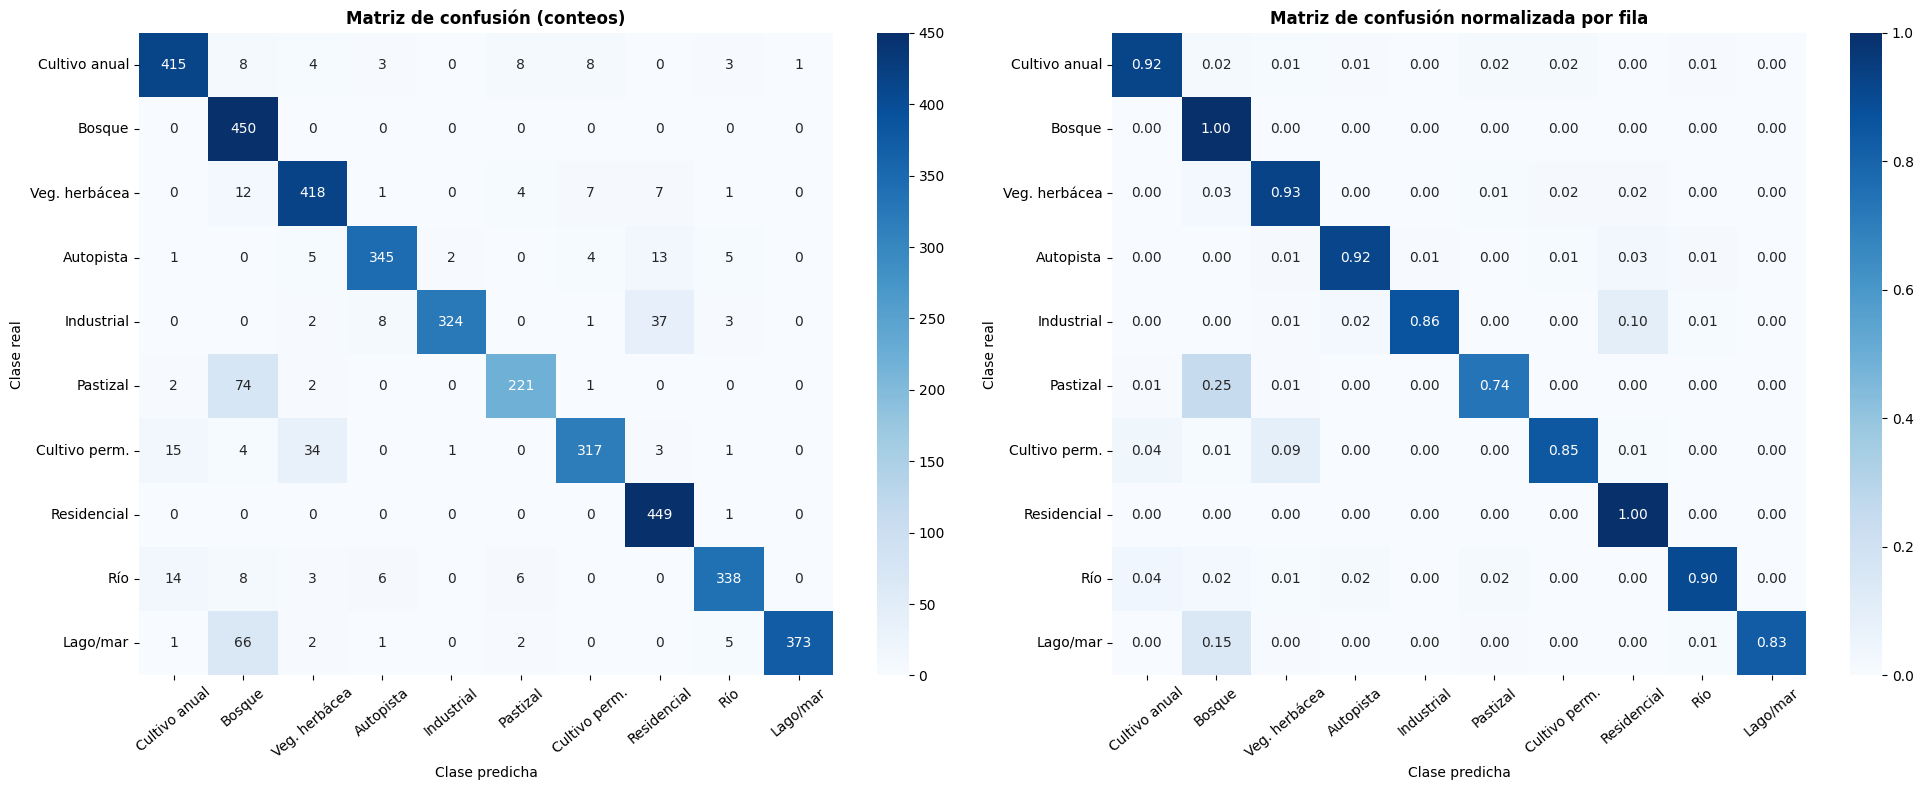

In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax[0])
ax[0].set_title("Matriz de confusión (conteos)", fontweight="bold")
ax[0].set_xlabel("Clase predicha"); ax[0].set_ylabel("Clase real")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax[1])
ax[1].set_title("Matriz de confusión normalizada por fila", fontweight="bold")
ax[1].set_xlabel("Clase predicha"); ax[1].set_ylabel("Clase real")
for a in ax:
    a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

### F.4 Curvas ROC por clase (One-vs-Rest) con AUC
**Qué hace este bloque:**
- La curva ROC es para problemas binarios, así que se aplica la estrategia **One-vs-Rest**: para cada clase se considera “esa clase” como positiva y “todas las demás” como negativa.
- `label_binarize` convierte las etiquetas a formato one-hot; con la probabilidad que el modelo asigna a cada clase, `roc_curve` calcula la tasa de verdaderos positivos (TPR) frente a la de falsos positivos (FPR) para todos los umbrales.
- **AUC** (área bajo la curva): 1.0 es perfecto y 0.5 equivale a adivinar al azar (diagonal punteada). También se reporta el AUC **macro** (promedio simple de las clases).
- Como los AUC de este problema son muy cercanos a 1, se agrega un zoom de la esquina superior izquierda para poder distinguir las curvas.

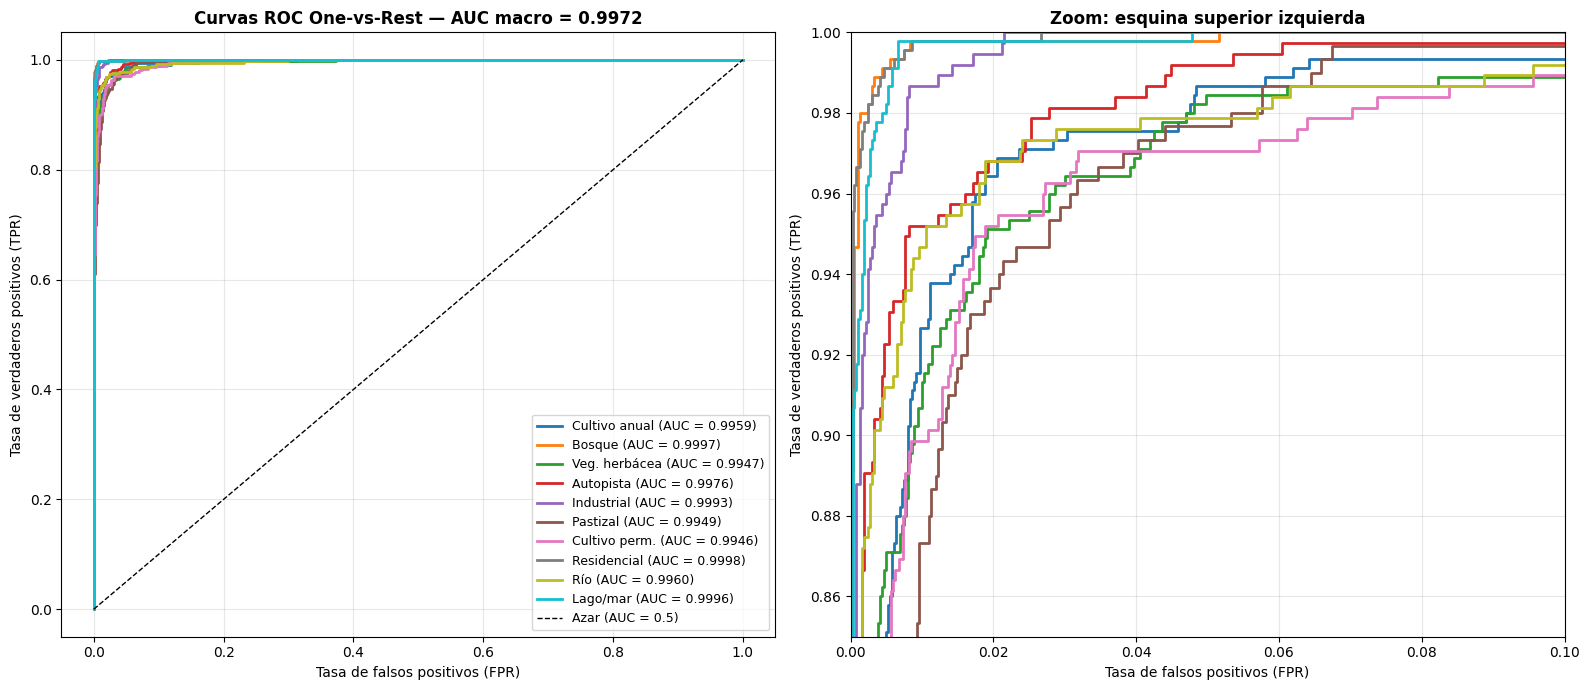

Residencial      0.9998
Bosque           0.9997
Lago/mar         0.9996
Industrial       0.9993
Autopista        0.9976
Río              0.9960
Cultivo anual    0.9959
Pastizal         0.9949
Veg. herbácea    0.9947
Cultivo perm.    0.9946
Name: AUC, dtype: float64

AUC macro: 0.9972


In [ ]:
y_test_bin = label_binarize(y_test, classes=range(NUM_CLASES))
colores_roc = sns.color_palette("tab10", NUM_CLASES)

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
auc_por_clase = {}
for i, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_por_clase[clase] = auc(fpr, tpr)
    for a in ax:
        a.plot(fpr, tpr, lw=2, color=colores_roc[i], label=f"{clase} (AUC = {auc_por_clase[clase]:.4f})")
auc_macro = np.mean(list(auc_por_clase.values()))
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
ax[0].set_title(f"Curvas ROC One-vs-Rest — AUC macro = {auc_macro:.4f}", fontweight="bold")
ax[1].set_xlim(0, 0.10); ax[1].set_ylim(0.85, 1.0)
ax[1].set_title("Zoom: esquina superior izquierda", fontweight="bold")
for a in ax:
    a.set_xlabel("Tasa de falsos positivos (FPR)"); a.set_ylabel("Tasa de verdaderos positivos (TPR)")
    a.grid(alpha=.3)
ax[0].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

print(pd.Series(auc_por_clase, name="AUC").sort_values(ascending=False).round(4))
print(f"\nAUC macro: {auc_macro:.4f}")

### F.5 Las 3 confusiones más frecuentes
**Qué hace este bloque:**
- Copia la matriz de confusión, pone la diagonal en 0 (los aciertos no interesan aquí) y ordena las celdas restantes de mayor a menor.
- Imprime los 3 pares (clase real → clase predicha) con más errores, junto con el porcentaje de la clase real que representan, y muestra ejemplos de imágenes de cada confusión para justificar la explicación con evidencia visual.

Top 3 confusiones (real -> predicha):
  1.       Pastizal -> Bosque        : 74 imágenes (24.7 % de las imágenes de Pastizal en test)
  2.       Lago/mar -> Bosque        : 66 imágenes (14.7 % de las imágenes de Lago/mar en test)
  3.     Industrial -> Residencial   : 37 imágenes (9.9 % de las imágenes de Industrial en test)


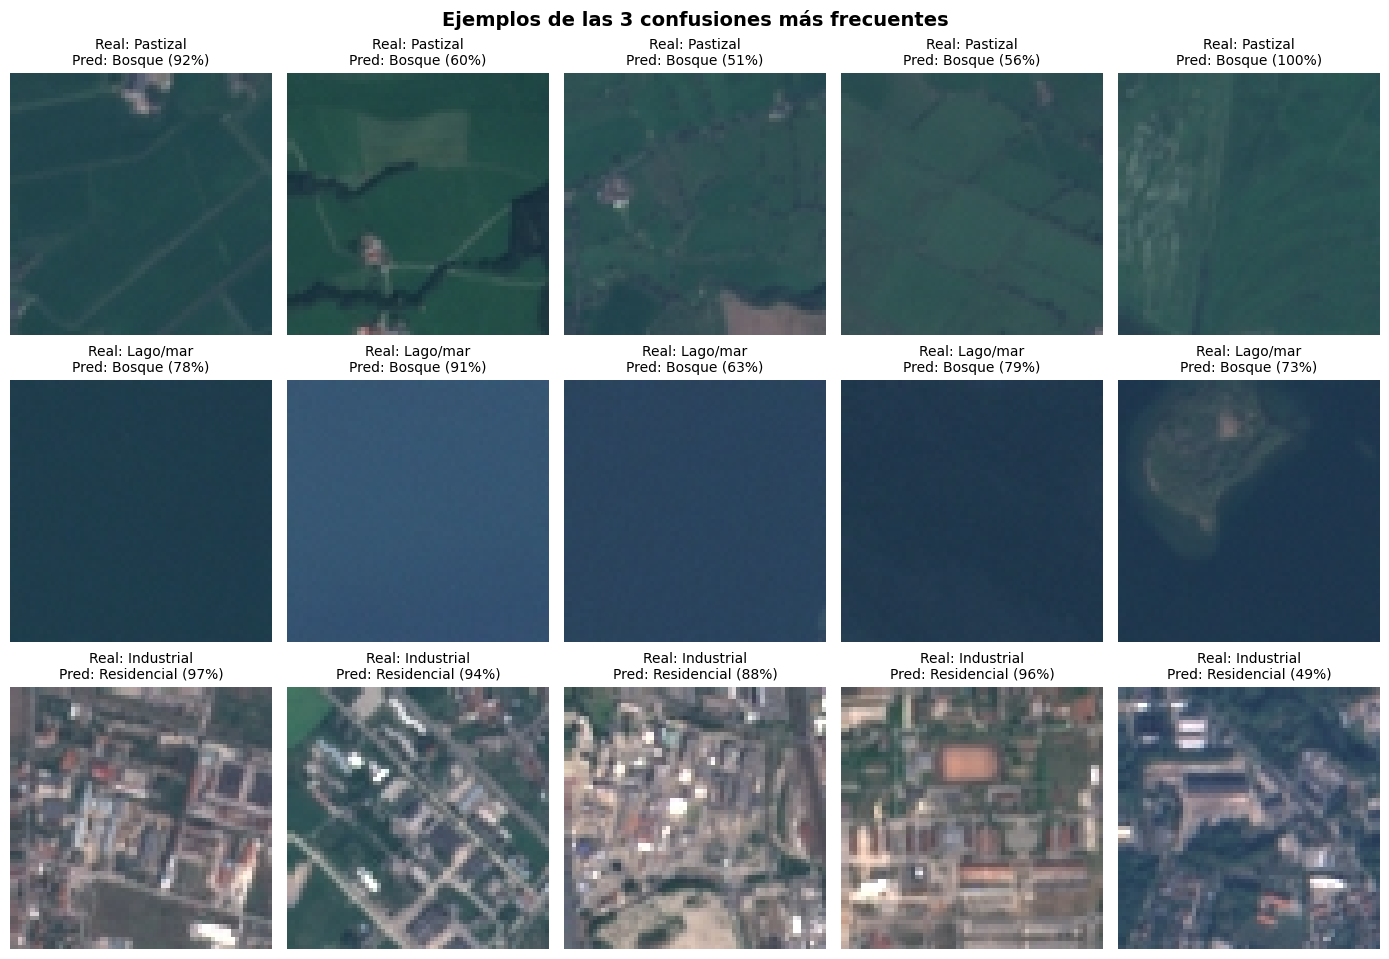

In [ ]:
errores = cm.copy()
np.fill_diagonal(errores, 0)
orden = np.dstack(np.unravel_index(np.argsort(errores.ravel(), kind="stable")[::-1], errores.shape))[0]
top3 = [(int(r), int(p)) for r, p in orden if errores[r, p] > 0][:3]

print("Top 3 confusiones (real -> predicha):")
for k, (r, p) in enumerate(top3, 1):
    print(f"  {k}. {CLASES[r]:>14s} -> {CLASES[p]:<14s}: {errores[r, p]} imágenes "
          f"({errores[r, p]/cm[r].sum()*100:.1f} % de las imágenes de {CLASES[r]} en test)")

# Hasta 5 ejemplos de cada confusión
fig, axes = plt.subplots(len(top3), 5, figsize=(14, 3.3*len(top3)), squeeze=False)
for fila, (r, p) in enumerate(top3):
    idx = np.where((y_test == r) & (y_pred == p))[0][:5]
    for col in range(5):
        ax = axes[fila, col]; ax.axis("off")
        if col < len(idx):
            ax.imshow(X_test[idx[col]])
            ax.set_title(f"Real: {CLASES[r]}\nPred: {CLASES[p]} ({y_proba[idx[col], p]*100:.0f}%)", fontsize=10)
plt.suptitle("Ejemplos de las 3 confusiones más frecuentes", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### F.5 Explicación de las confusiones (párrafo)

Las 3 confusiones más frecuentes en test (celda anterior) fueron:

1. **Pastizal → Bosque** (74 imágenes, **24,7 %** de las de Pastizal). Son campos de verde oscuro muy parecidos a la copa de un bosque a 10 m por píxel; la única pista (los lindes finos entre parcelas, zanjas oscuras o alguna construcción aislada) ocupa pocos píxeles. La confianza del error va de 51 % a 100 % en los ejemplos.
2. **Lago/mar → Bosque** (66 imágenes, **14,7 %** de las de Lago/mar). Son las dos clases más oscuras del dataset (en B.6b, canal rojo medio ≈ 47 para Lago/mar y ≈ 38 para Bosque, valores leídos del gráfico) y ambas son superficies casi uniformes. En los ejemplos el agua es un azul oscuro homogéneo y sin estructuras (confianza del error de 63–91 %); en uno de ellos aparece además una isla con vegetación, es decir, una imagen que mezcla dos usos de suelo.
3. **Industrial → Residencial** (37 imágenes, **9,9 %** de las de Industrial). Ambas son texturas de edificaciones con calles y techos; lo que las distingue es el tamaño de las construcciones, difícil de apreciar a 64×64, y varios ejemplos mezclan edificios, calles y zonas verdes (confianza de 49–97 %).

**Un patrón que va más allá de la similitud visual.** Los errores son *asimétricos*: Bosque tiene recall de **100,00 %** pero precision de solo **72,35 %** (≈ 172 falsos positivos, derivados de la precision, de los cuales 140 vienen de Pastizal y Lago/mar), mientras que Lago/mar tiene precision de **99,73 %** y recall de **82,89 %**. Además, el AUC de Lago/mar (**0,9996**) y el de Bosque (**0,9997**) están entre los más altos. Es decir, el modelo ordena bien las probabilidades (a las imágenes de lago les asigna más probabilidad de “lago” que a las demás), pero la decisión por `argmax` queda desplazada hacia Bosque: no solo falta información visual, hay un **sesgo sistemático**. Este sesgo apareció también en una ejecución previa del mismo notebook (Bosque con recall de 99,78 % y precision de 68,24 %). La explicación es una *hipótesis* compatible con la inestabilidad de la validación observada en D.4 (diferencias entre el comportamiento en entrenamiento, con augmentation y dropout, y en evaluación), pero **no se verificó** en este trabajo; sería lo primero a revisar en una versión futura (por ejemplo, reentrenando con menos augmentation de contraste o sin Dropout antes de BatchNorm, o calibrando las probabilidades).

En general, hay también imágenes que mezclan dos usos de suelo (una isla en un lago, una zona industrial rodeada de viviendas) y cuya etiqueta sería dudosa incluso para una persona.

### F.6 Análisis de errores visual (≥ 10 imágenes mal clasificadas)
**Qué hace este bloque:**
- Selecciona las imágenes de test mal clasificadas y las ordena por la **confianza** con la que el modelo se equivocó (probabilidad de la clase predicha), mostrando primero los errores “más seguros”.
- Dibuja 15 en una grilla de 3×5 con su clase real (verde), la predicha (rojo) y la confianza. Esto permite ver patrones: imágenes que mezclan dos usos de suelo, parcelas sin textura visible, nubes o bruma, o etiquetas dudosas.

Imágenes mal clasificadas: 400 de 4050 (9.9 %)


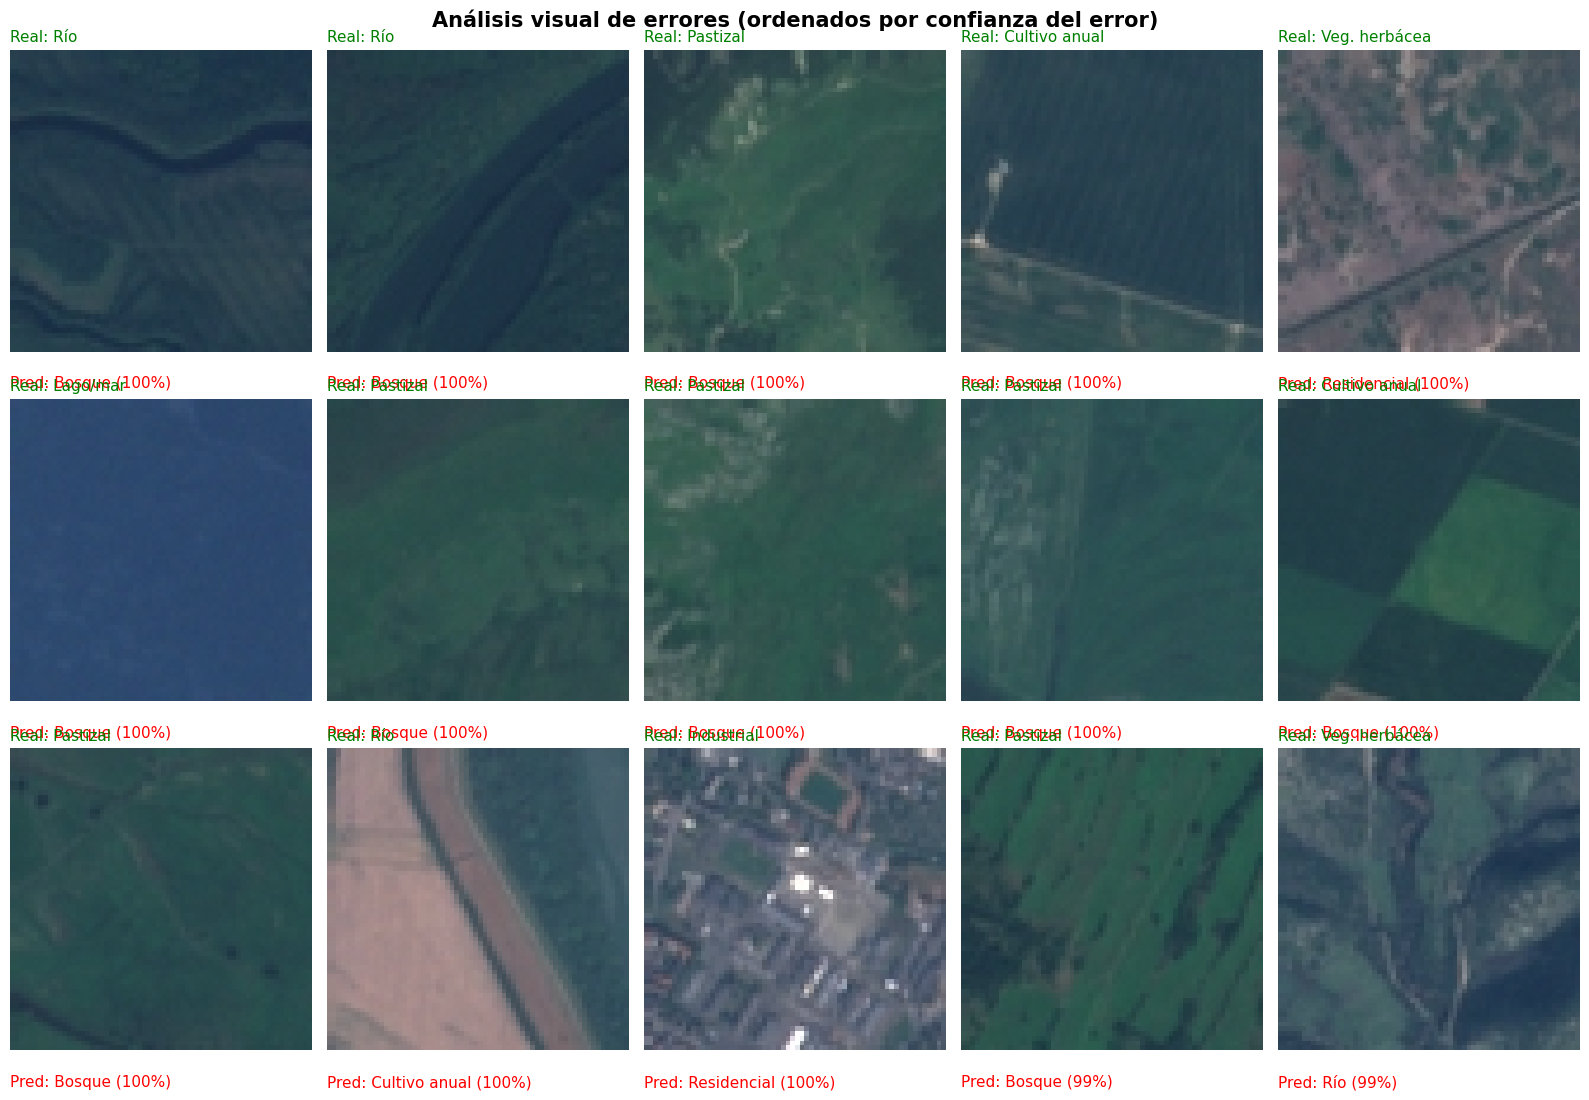

In [ ]:
mal = np.where(y_pred != y_test)[0]
print(f"Imágenes mal clasificadas: {len(mal)} de {len(y_test)} ({len(mal)/len(y_test)*100:.1f} %)")
mal = mal[np.argsort(-y_proba[mal, y_pred[mal]])]   # ordenar por confianza del error

n = min(15, len(mal))
fig, axes = plt.subplots(3, 5, figsize=(16, 11))
for k, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if k < n:
        i = mal[k]
        ax.imshow(X_test[i])
        ax.set_title(f"Real: {CLASES[y_test[i]]}", color="green", fontsize=11, loc="left")
        ax.text(0.0, -0.08, f"Pred: {CLASES[y_pred[i]]} ({y_proba[i, y_pred[i]]*100:.0f}%)",
                color="red", fontsize=11, transform=ax.transAxes, va="top")
plt.suptitle("Análisis visual de errores (ordenados por confianza del error)", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

### F.7 Guardar y recargar el modelo final
**Qué hace este bloque:** guarda la CNN mejorada en el formato nativo de Keras (`.keras`) para poder cargarla después con `keras.models.load_model` sin reentrenar, y la vuelve a cargar para comprobar que predice lo mismo.

In [ ]:
cnn_mejorada.save("cnn_mejorada_eurosat.keras")
modelo_cargado = keras.models.load_model("cnn_mejorada_eurosat.keras")
iguales = np.array_equal(np.argmax(modelo_cargado.predict(X_test[:50], verbose=0), axis=1), y_pred[:50])
print("Modelo guardado y recargado correctamente. Predicciones idénticas:", iguales)

Modelo guardado y recargado correctamente. Predicciones idénticas: True


### F.8 Resumen numérico de todos los resultados
**Qué hace este bloque:** reúne en un solo diccionario las cifras clave del notebook (las que se citan en los párrafos de análisis y en las conclusiones), para tenerlas a la vista en la defensa.

In [ ]:
resultados = {
    "params_base": int(params_base), "params_mejorada": int(params_mejorada),
    "base": {k: round(float(v), 4) for k, v in diag_base.items()},
    "mejorada": {k: round(float(v), 4) for k, v in diag_mejorada.items()},
    "epocas_mejorada": len(historia_mejorada.history["loss"]),
    "acc_val_base": round(float(acc_val_base), 4), "acc_val_mejorada": round(float(acc_val_mej), 4),
    "acc_test_base": round(float(acc_test_base), 4), "acc_test_mejorada": round(float(acc_test), 4),
    "loss_test_mejorada": round(float(loss_test), 4),
    "auc_macro": round(float(auc_macro), 4),
    "auc_por_clase": {k: round(float(v), 4) for k, v in auc_por_clase.items()},
    "f1_por_clase": reporte["f1-score"].round(4).to_dict(),
    "top3_confusiones": [(CLASES[r], CLASES[p], int(errores[r, p])) for r, p in top3],
    "optimizadores": tabla_opt.round(4).reset_index().to_dict(orient="records"),
    "errores_test": int(len(mal)),
}
print(json.dumps(resultados, indent=2, ensure_ascii=False))

{
  "params_base": 1143242,
  "params_mejorada": 424042,
  "base": {
    "train_acc": 0.9804,
    "val_acc": 0.8436,
    "best_val_acc": 0.8466,
    "brecha": 0.1369,
    "epoca_min_val_loss": 6.0,
    "min_val_loss": 0.4991,
    "val_loss_final": 0.9302,
    "train_loss_final": 0.0572
  },
  "mejorada": {
    "train_acc": 0.9518,
    "val_acc": 0.8645,
    "best_val_acc": 0.9059,
    "brecha": 0.0873,
    "epoca_min_val_loss": 21.0,
    "min_val_loss": 0.3639,
    "val_loss_final": 0.4812,
    "train_loss_final": 0.2119
  },
  "epocas_mejorada": 29,
  "acc_val_base": 0.8436,
  "acc_val_mejorada": 0.8898,
  "acc_test_base": 0.8388,
  "acc_test_mejorada": 0.9012,
  "loss_test_mejorada": 0.3498,
  "auc_macro": 0.9972,
  "auc_por_clase": {
    "Cultivo anual": 0.9959,
    "Bosque": 0.9997,
    "Veg. herbácea": 0.9947,
    "Autopista": 0.9976,
    "Industrial": 0.9993,
    "Pastizal": 0.9949,
    "Cultivo perm.": 0.9946,
    "Residencial": 0.9998,
    "Río": 0.996,
    "Lago/mar": 0.9996
 

## SECCIÓN G — Conclusiones

**1. Resumen de resultados.** La CNN mejorada alcanzó un **accuracy de 90,12 % en test** (4 050 imágenes; 400 errores, 9,9 %), frente a **83,88 %** de la CNN base, con un **AUC macro One-vs-Rest de 0,9972** y un F1 macro de 0,9001. La mejor clase fue **Residencial** (F1 = 0,9364, seguida de Autopista con 0,9337) y la peor **Pastizal** (F1 = 0,8170), seguida de Bosque (0,8396) y Cultivo permanente (0,8892). Contra lo esperado, Bosque, de apariencia muy característica, quedó entre las peores: el modelo tiende a predecir “Bosque” de más (recall 100,00 % pero precision 72,35 %), y por eso pierde imágenes de Pastizal (recall 73,67 %) y de Lago/mar (recall 82,89 %).

**2. Impacto de la regularización.** La CNN base memorizó el entrenamiento (train 98,04 % frente a val 84,36 %, brecha de 13,69 pp, `val_loss` creciente desde la época 6). Con data augmentation, Batch Normalization, Dropout, GAP y L2 la brecha bajó a 8,73 pp (≈ 4,91 pp en la época 21 que se conserva), la validación mejoró **+4,62 puntos** (88,98 % frente a 84,36 %), el test mejoró **+6,24 puntos** y el modelo usó **62,9 % menos parámetros** (424 042 frente a 1 143 242). Parte de la ventaja proviene de que EarlyStopping restaura los mejores pesos (con los de la última época la validación habría sido 86,45 %, ≈ +2,1 puntos sobre la base), y la validación siguió siendo inestable entre épocas; no se hizo ablación, por lo que no se puede medir el aporte de cada técnica. En resumen, la regularización redujo el overfitting y mejoró el resultado con un modelo más pequeño, pero no resolvió por completo la inestabilidad.

**3. Confusiones más frecuentes.** Las tres principales fueron **Pastizal → Bosque** (74 imágenes), **Lago/mar → Bosque** (66) e **Industrial → Residencial** (37). Se explican en parte por similitud visual: campos verdes oscuros parecidos a copas de árboles, superficies oscuras y uniformes (agua y bosque) y texturas de edificaciones difíciles de distinguir por tamaño a 64×64 y 10 m por píxel. Pero el patrón asimétrico (AUC de 0,9996 en Lago/mar con recall de solo 82,89 %) sugiere además un **sesgo sistemático hacia Bosque**, que se repitió en dos ejecuciones y es una hipótesis no verificada.

**4. Lecciones aprendidas.**
- Una CNN sin regularización llega a ≈ 98 % en train mientras la validación se estanca; las curvas train/val, y en especial la `val_loss`, son imprescindibles para detectarlo.
- La mayoría de los parámetros de una CNN clásica está en la capa densa posterior al `Flatten` (91,8 % en la base); GAP reduce el modelo y el overfitting a la vez.
- La data augmentation debe elegirse según el dominio: en imágenes satelitales los giros verticales y las rotaciones son válidos porque no existe “arriba”.
- Los callbacks automatizan cuándo parar y cuándo afinar, pero hay que comparar con justicia: la CNN mejorada se evalúa con sus mejores pesos y la base con los de la última época.
- Con una sola corrida y una validación tan ruidosa, el ranking de optimizadores por mejor `val_accuracy` cambió de una ejecución a otra (SGD > Adam > RMSprop en una, RMSprop > Adam > SGD en la otra); lo que se mantuvo es que Adam entrena más rápido y que RMSprop es el más errático.
- El accuracy global no basta: un AUC alto puede convivir con un recall bajo (Lago/mar), y solo el reporte por clase y la matriz de confusión lo revelaron.

**5. Limitaciones y posibles mejoras.**
- *Limitaciones:* solo se usaron las 3 bandas RGB, cuando Sentinel-2 ofrece 13 bandas (por ejemplo, el infrarrojo cercano distingue muy bien tipos de vegetación); resolución de 64×64 a 10 m por píxel, que borra detalles como hileras de cultivo; todas las imágenes son de Europa, por lo que el modelo podría no generalizar a otros paisajes (por ejemplo, Perú); un solo split y una sola corrida por modelo y por optimizador, con resultados que varían entre ejecuciones (el accuracy en test de la CNN mejorada fue de 88,52 % en una ejecución previa y de 90,12 % en esta); validación inestable entre épocas; el sesgo hacia Bosque quedó sin investigar; y los optimizadores se compararon sin callbacks.
- *Mejoras:* transfer learning con un modelo preentrenado en ImageNet (p. ej. EfficientNetB0 o ResNet50), ya que los autores del dataset reportan una exactitud de hasta 98,57 % (Helber et al., 2019); usar la versión multiespectral (`eurosat/all`) con las 13 bandas; revisar la combinación Dropout + BatchNorm + augmentation de contraste; calibrar las probabilidades; augmentation más rica (brillo, MixUp/CutMix); validación cruzada con varias semillas; y búsqueda de hiperparámetros (lr, dropout, L2) con KerasTuner.